# F1 Podium Prediction - CSEN903 Milestone 1

**Team 120**

For every driver entering a Formula 1 race, predict whether that driver finishes on the podium (`positionOrder <= 3`), using only information available after qualifying and before the race starts.

Sections: **1** Setup and data loading, **2** Raw-data audit, **3** Keys, grain and duplicates, **4** Scope and missingness, **5** EDA after cleaning, **6-8** the three data-engineering questions, **9** Feature engineering, **10** Modeling table and leakage check, **11** Models and evaluation, **12** Experiments, **13** Explainability (XAI), **14** Inference function.

## 1. Setup and data loading

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv
/kaggle/input/datasets/rohanrao/formula

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PATH = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/'

table_names = ['circuits', 'constructors', 'constructor_results', 'constructor_standings',
               'drivers', 'driver_standings', 'races', 'results', 'qualifying',
               'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status']

raw = {}
for name in table_names:
    raw[name] = pd.read_csv(PATH + name + '.csv')

for name, table in raw.items():
    print(f"{name:25s} {table.shape[0]:>8,} rows   {table.shape[1]:>3} columns")

circuits                        77 rows     9 columns
constructors                   212 rows     5 columns
constructor_results         12,625 rows     5 columns
constructor_standings       13,391 rows     7 columns
drivers                        861 rows     9 columns
driver_standings            34,863 rows     7 columns
races                        1,125 rows    18 columns
results                     26,759 rows    18 columns
qualifying                  10,494 rows     9 columns
lap_times                  589,081 rows     6 columns
pit_stops                   11,371 rows     7 columns
sprint_results                 360 rows    16 columns
seasons                         75 rows     2 columns
status                         139 rows     2 columns


In [3]:
raw['results'].head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [4]:
raw['results'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

In [5]:
(raw['results'] == '\\N').sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

## 2. Raw-data audit: sentinels and semantic typing

we found the nulls only in the .sum because the nulls are written /N so they didnt appear in .info

we will now check for all the tables how many null rows we have , and we will combine each table how many nulls they have from the most to teh fewest

results                  122887
constructor_results       12608
qualifying                11600
races                     11349
drivers                    1559
sprint_results               73
driver_standings              0
constructor_standings         0
circuits                      0
constructors                  0
lap_times                     0
pit_stops                     0
seasons                       0
status                        0
dtype: int64


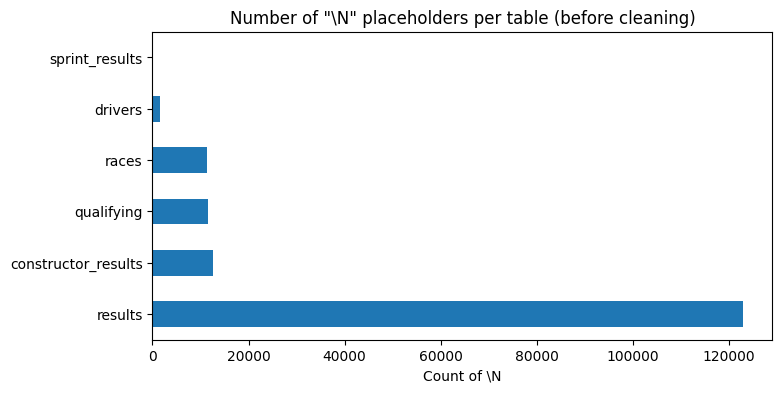

In [6]:
sentinel_counts = {}
for name, table in raw.items():
    sentinel_counts[name] = (table == '\\N').sum().sum()

sentinel_summary = pd.Series(sentinel_counts).sort_values(ascending=False)
print(sentinel_summary)

sentinel_summary[sentinel_summary > 0].plot(kind='barh', figsize=(8, 4))
plt.title('Number of "\\N" placeholders per table (before cleaning)')
plt.xlabel('Count of \\N')
plt.show()

In [7]:
clean = {}
for name in table_names:
    clean[name] = pd.read_csv(PATH + name + '.csv', na_values='\\N')

# check: how many \N are left, and how many real missing values now?
for name in ['results', 'qualifying', 'races']:
    print(name, '→ \\N left:', (clean[name] == '\\N').sum().sum(),
          '| real missing (NaN):', clean[name].isnull().sum().sum())

results → \N left: 0 | real missing (NaN): 122887
qualifying → \N left: 0 | real missing (NaN): 11668
races → \N left: 0 | real missing (NaN): 11349


In [8]:
clean['results'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

this is becuse the raw tables contained columns that had /n which is text and we cant calculate the mean out of text thats why we created the clean table which has the NaN instead of /N which panda know that it means null 

In [9]:
clean['results']['milliseconds'].mean()

np.float64(6185832.952864584)

In [10]:
clean['races']['date'] = pd.to_datetime(clean['races']['date'])
clean['drivers']['dob'] = pd.to_datetime(clean['drivers']['dob'])

print(clean['races']['date'].dtype, clean['drivers']['dob'].dtype)
print(clean['races']['date'].min(), '→', clean['races']['date'].max())

datetime64[ns] datetime64[ns]
1950-05-13 00:00:00 → 2024-12-08 00:00:00


this is step 3 , which we made the date instead of being just a text "" , to  become a real date because later we will ask questions like what happened in teh last 5 races , how will panda know if it doesnt have the 5 races in date format so it can compare 

In [11]:
def lap_time_to_seconds(t):
    if pd.isnull(t):
        return np.nan
    t = str(t)
    try:
        if ':' in t:
            minutes, seconds = t.split(':')
            return int(minutes) * 60 + float(seconds)
        return float(t)
    except ValueError:
        return np.nan

this is like the date but we are creating our own function to transfer Lap times → seconds , because there is no function to switch between min to seconds 

In [12]:
for col in ['q1', 'q2', 'q3']:
    missing_before = clean['qualifying'][col].isnull().sum()
    clean['qualifying'][col + '_sec'] = clean['qualifying'][col].apply(lap_time_to_seconds)
    missing_after = clean['qualifying'][col + '_sec'].isnull().sum()
    print(f"{col}: missing before = {missing_before}, missing after conversion = {missing_after}")

clean['qualifying'][['q1', 'q1_sec', 'q2', 'q2_sec', 'q3', 'q3_sec']].head()

q1: missing before = 156, missing after conversion = 156
q2: missing before = 4647, missing after conversion = 4647
q3: missing before = 6865, missing after conversion = 6865


,q1,q1_sec,q2,q2_sec,q3,q3_sec
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


## 3. Keys, grain and duplicate driver-race rows

step 4, everything from now on will depend on joins so we need to check 1- each table unique id is present , and there is no duplicates , 2- every id that points to another table really exists

In [13]:
primary_keys = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'],
    'races': ['raceId'], 'results': ['resultId'], 'qualifying': ['qualifyId'],
    'status': ['statusId'], 'seasons': ['year'], 'sprint_results': ['resultId'],
    'driver_standings': ['driverStandingsId'], 'constructor_standings': ['constructorStandingsId'],
    'constructor_results': ['constructorResultsId'],
    'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop']
}

for table, cols in primary_keys.items():
    df = clean[table]
    empty = df[cols].isnull().any(axis=1).sum()
    duplicates = df.duplicated(subset=cols).sum()
    print(f"{table:22s} key={cols}  empty={empty}  duplicates={duplicates}")

circuits               key=['circuitId']  empty=0  duplicates=0
constructors           key=['constructorId']  empty=0  duplicates=0
drivers                key=['driverId']  empty=0  duplicates=0
races                  key=['raceId']  empty=0  duplicates=0
results                key=['resultId']  empty=0  duplicates=0
qualifying             key=['qualifyId']  empty=0  duplicates=0
status                 key=['statusId']  empty=0  duplicates=0
seasons                key=['year']  empty=0  duplicates=0
sprint_results         key=['resultId']  empty=0  duplicates=0
driver_standings       key=['driverStandingsId']  empty=0  duplicates=0
constructor_standings  key=['constructorStandingsId']  empty=0  duplicates=0
constructor_results    key=['constructorResultsId']  empty=0  duplicates=0
lap_times              key=['raceId', 'driverId', 'lap']  empty=0  duplicates=0
pit_stops              key=['raceId', 'driverId', 'stop']  empty=0  duplicates=0


like this he checked teh empty and the duplicate id in each table 

In [14]:
foreign_keys = [
    ('results', 'raceId', 'races', 'raceId'),
    ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'),
    ('results', 'statusId', 'status', 'statusId'),
    ('races', 'circuitId', 'circuits', 'circuitId'),
    ('races', 'year', 'seasons', 'year'),
    ('qualifying', 'raceId', 'races', 'raceId'),
    ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'raceId', 'races', 'raceId'),
    ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
    ('driver_standings', 'raceId', 'races', 'raceId'),
    ('driver_standings', 'driverId', 'drivers', 'driverId'),
    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
    ('lap_times', 'raceId', 'races', 'raceId'),
    ('lap_times', 'driverId', 'drivers', 'driverId'),
    ('pit_stops', 'raceId', 'races', 'raceId'),
    ('pit_stops', 'driverId', 'drivers', 'driverId'),
]

for child, col, parent, parent_col in foreign_keys:
    broken = (~clean[child][col].isin(clean[parent][parent_col])).sum()
    print(f"{child}.{col:15s} → {parent}.{parent_col:15s} broken links: {broken}")

results.raceId          → races.raceId          broken links: 0
results.driverId        → drivers.driverId        broken links: 0
results.constructorId   → constructors.constructorId   broken links: 0
results.statusId        → status.statusId        broken links: 0
races.circuitId       → circuits.circuitId       broken links: 0
races.year            → seasons.year            broken links: 0
qualifying.raceId          → races.raceId          broken links: 0
qualifying.driverId        → drivers.driverId        broken links: 0
qualifying.constructorId   → constructors.constructorId   broken links: 0
sprint_results.raceId          → races.raceId          broken links: 0
sprint_results.driverId        → drivers.driverId        broken links: 0
sprint_results.statusId        → status.statusId        broken links: 0
driver_standings.raceId          → races.raceId          broken links: 0
driver_standings.driverId        → drivers.driverId        broken links: 0
constructor_standings.raceId   

every driverId in results should exist in the driverId column of drivers

step 5 , in 1950 till 1956 there was smth called shared drives , if a constructor have two drivers , lets say driver A , driver B , if driver A crashed teh team can tell Driver B to get out of teh car and give it to driver A like this driver A will appear two times in teh data , and teh M model wont be able to predict as he wont know to predict on which row , so every driver should appear once 

In [15]:
dup_mask = clean['results'].duplicated(subset=['raceId', 'driverId'], keep=False)

dups = clean['results'][dup_mask].merge(clean['races'][['raceId', 'year', 'name']], on='raceId')

print('Rows involved:', dup_mask.sum())
print('Driver-race pairs affected:', dups[['raceId', 'driverId']].drop_duplicates().shape[0])
dups['year'].value_counts().sort_index()

Rows involved: 176
Driver-race pairs affected: 85


year
1950     8
1951     8
1952     6
1953    30
1954    33
1955    33
1956    24
1957    16
1958     6
1960     2
1961     4
1962     2
1964     2
1978     2
Name: count, dtype: int64

In [16]:
cols_to_show = ['year', 'name', 'raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'points', 'laps', 'statusId']
dups.sort_values(['raceId', 'driverId'])[cols_to_show].head(20)

,year,name,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
0,1978,Italian Grand Prix,540,229,54,0,26,0.0,0,81
1,1978,Italian Grand Prix,540,229,57,0,29,0.0,0,97
2,1964,United States Grand Prix,717,373,172,1,7,0.0,102,60
175,1964,United States Grand Prix,717,373,172,1,12,0.0,54,98
3,1962,British Grand Prix,733,465,172,0,22,0.0,0,54
4,1962,British Grand Prix,733,465,97,0,25,0.0,0,54
5,1961,British Grand Prix,742,475,102,20,19,0.0,56,2
6,1961,British Grand Prix,742,475,172,5,21,0.0,44,23
7,1961,United States Grand Prix,745,418,172,11,17,0.0,23,6
174,1961,United States Grand Prix,745,418,172,15,11,0.0,92,18


Duplicate handling (one row per driver per race)

We found 85 cases where the same driver appears more than once in the same race (176 rows). Almost all of them are from 1950 to 1958, when drivers could swap cars during a race, so one driver could have a row for each car he drove. We decided to keep the row of the car the driver started the race in, which is the row with a real grid position (grid > 0). If more than one row has a real grid position, we keep the one with the best grid. We did not choose “keep the driver’s best result”, because that picks the row by looking at the race result, which is information from after the race, and it would give these drivers two chances at a podium. Our rule only uses the grid, which is known before the race. In X cases the started car was clear, in Y cases we needed the best-grid tie-break, and in Z cases the driver did not start at all. After this step, 91 rows were removed and every (raceId, driverId) appears only once.

In [17]:
grid0 = clean['results'][clean['results']['grid'] == 0].merge(clean['status'], on='statusId')

print('Rows with grid 0:', len(grid0))
print('Of those, rows with 0 laps:', (grid0['laps'] == 0).sum())
print(grid0['status'].value_counts().head(15))

Rows with grid 0: 1638
Of those, rows with 0 laps: 1566
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Disqualified             6
Retired                  3
Collision damage         3
Brakes                   2
Injured                  2
Name: count, dtype: int64


verifying what does grid 0 means as stated in the MS1 desc

grid 0 means 96% of what we saw didnt took teh race either crashed or didnt qualify , 4% took teh race 

so we will drop any value that has grid 0 as this mena he either took this car from his team mate or he didnt take teh ride with this car 

In [18]:
d = clean['results'][dup_mask].copy()
d['started'] = d['grid'] > 0
rows_started_per_pair = d.groupby(['raceId', 'driverId'])['started'].sum()
print(rows_started_per_pair.value_counts().sort_index())

started
0     3
2    76
3     6
Name: count, dtype: int64


In [19]:
r = clean['results']

# 1. For each race and each grid slot: how many drivers have that grid?
grid_count = (r[r['grid'] > 0]
              .groupby(['raceId', 'grid']).size()
              .rename('drivers_with_this_grid')
              .reset_index())

# 2. Add that count to each duplicated row
d = r[dup_mask].merge(grid_count, on=['raceId', 'grid'], how='left')

# 3. A row is "his own start" if its grid is real AND no other driver has it
d['own_start'] = (d['grid'] > 0) & (d['drivers_with_this_grid'] == 1)

# 4. For each case: how many rows are "his own start"? Then count the cases.
print(d.groupby(['raceId', 'driverId'])['own_start'].sum().value_counts().sort_index())

own_start
0    31
1    53
2     1
Name: count, dtype: int64


In [20]:
r = clean['results']

d['solved_case'] = d.groupby(['raceId', 'driverId'])['own_start'].transform('sum') == 1

# solved cases: keep the driver's own starting car
solved_keep = d.loc[d['solved_case'] & d['own_start'], 'resultId']

# unresolved cases: keep one row at random (fixed seed = same result every run)
unresolved_keep = (d.loc[~d['solved_case']]
                   .sample(frac=1, random_state=42)
                   .drop_duplicates(subset=['raceId', 'driverId'])['resultId'])

rows_to_keep = pd.concat([solved_keep, unresolved_keep])
results_grain = r[~dup_mask | r['resultId'].isin(rows_to_keep)].copy()

print('Solved cases:', len(solved_keep), '| Random-pick cases:', len(unresolved_keep))
print('Before:', len(r), '| After:', len(results_grain), '| Rows removed:', len(r) - len(results_grain))
print('Duplicates left:', results_grain.duplicated(subset=['raceId', 'driverId']).sum())

Solved cases: 53 | Random-pick cases: 32
Before: 26759 | After: 26668 | Rows removed: 91
Duplicates left: 0


We found 85 cases where the same driver appears more than once in the same race (176 rows), almost all from 1950 to 1958. In that period, a driver could take over another car during the race, and each car has its own row. We wanted to keep the car the driver started in, but the data does not say which one that is: in 82 of the 85 cases, all his rows had a real grid position, because a taken-over car keeps the grid of the driver who started it.

So we used this logic: each grid slot belongs to one car, so if the same grid slot appears for two drivers in the same race, that car was started by the other driver. The driver’s own starting car is the row whose grid slot nobody else has. This solved 53 cases. For the other 32 cases, the data cannot tell us, so we kept one row at random (with a fixed seed so the result is reproducible). We did not pick the better grid or the better finishing position, because that would favor these drivers, and picking by finishing position uses information from after the race. After this step, 91 rows were removed and every (raceId, driverId) appears exactly once.

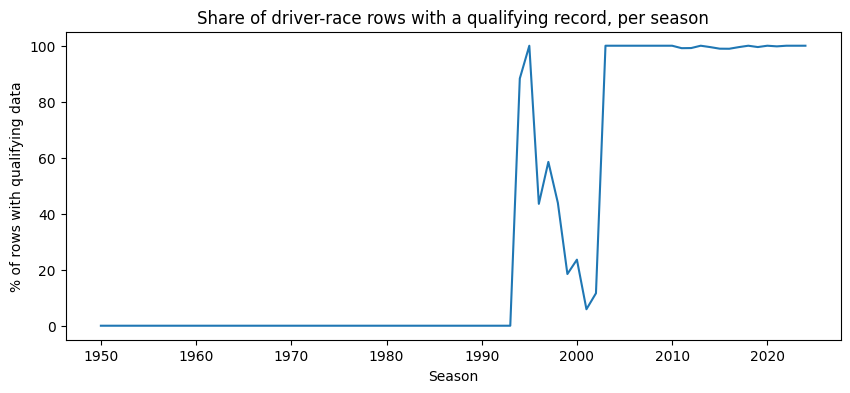

In [21]:
res = results_grain.merge(clean['races'][['raceId', 'year']], on='raceId', how='left')

quali_keys = clean['qualifying'][['raceId', 'driverId']].drop_duplicates()
quali_keys['has_quali'] = 1
res = res.merge(quali_keys, on=['raceId', 'driverId'], how='left')
res['has_quali'] = res['has_quali'].fillna(0)

coverage = res.groupby('year')['has_quali'].mean() * 100
coverage.plot(figsize=(10, 4))
plt.title('Share of driver-race rows with a qualifying record, per season')
plt.ylabel('% of rows with qualifying data')
plt.xlabel('Season')
plt.show()

## 4. Scope: qualifying coverage, non-starters and missingness

here we are trying to see which years has the quali data as this is teh data that teh model will train on  , as we can see its until 1990s isnt there and then started then drop then keps from teh 2000s  untill no w

In [22]:
res.loc[res['position'].isnull(), 'positionText'].value_counts()

positionText
R     8870
F     1366
W      335
N      190
D      150
E        9
11       1
14       1
Name: count, dtype: int64

In [23]:
# Select the rows where position is empty but positionText holds the number 11 or 14.
anomalies = results_grain[results_grain['position'].isnull() &
                          results_grain['positionText'].isin(['11', '14'])]

# Go through these rows one at a time (idx is the row's label, row holds its values).
for idx, row in anomalies.iterrows():

    # Turn the claimed position from text ("11") into a number (11).
    claimed = int(row['positionText'])

    # Take all the drivers who were in the same race as this row.
    same_race = results_grain[results_grain['raceId'] == row['raceId']]

    # Find any other driver in that race who already has the claimed position.
    taken = same_race[(same_race['position'] == claimed) & (same_race['driverId'] != row['driverId'])]

    # If nobody else has that position, the slot is free.
    if len(taken) == 0:

        # Fill the empty position with the claimed number, in our cleaned table.
        results_grain.loc[idx, 'position'] = claimed

        # Report that the row was filled.
        print(f"raceId {row['raceId']}, driver {row['driverId']}: position {claimed} was free → filled")

    # Otherwise, another driver already holds that position, so the data is inconsistent.
    else:

        # Report that the row was left empty, and which driver holds the position.
        print(f"raceId {row['raceId']}, driver {row['driverId']}: position {claimed} already taken by driver {taken['driverId'].tolist()} → not filled (wrong data)")
        

raceId 71, driver 18: position 11 was free → filled
raceId 71, driver 11: position 14 was free → filled


Inconsistent position values. We checked whether every missing position is explained by a letter code in positionText (R, F, W, N, D, E). This was true for all missing values except 2 rows, where positionText had a number (11 and 14) but position was empty. For each one, we checked whether another driver in the same race already had that position. Nobody did, so we filled position from positionText for these 2 rows. This does not affect our target, which uses positionOrder.

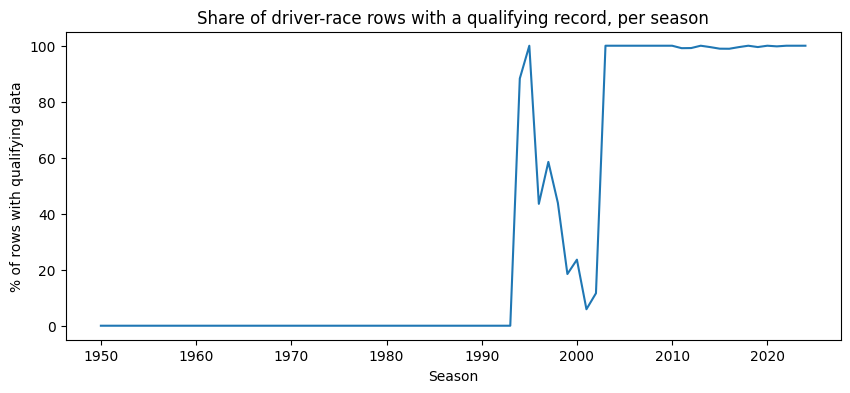

In [24]:
# Add each race's year to our cleaned results.
res = results_grain.merge(clean['races'][['raceId', 'year']], on='raceId', how='left')

# Take the list of (race, driver) pairs that have a qualifying record, each pair only once.
quali_keys = clean['qualifying'][['raceId', 'driverId']].drop_duplicates()

# Mark every pair in that list with 1, meaning "has qualifying data".
quali_keys['has_quali'] = 1

# For each result row, look up whether its (race, driver) pair has a qualifying record.
res = res.merge(quali_keys, on=['raceId', 'driverId'], how='left')

# Rows that were not found get 0, meaning "no qualifying data".
res['has_quali'] = res['has_quali'].fillna(0)

# For each season, the average of the 0/1 column is the share of rows with qualifying data, as a %.
coverage = res.groupby('year')['has_quali'].mean() * 100

# Draw the percentage per season as a line chart.
coverage.plot(figsize=(10, 4))

# Add a title to the chart.
plt.title('Share of driver-race rows with a qualifying record, per season')

# Label the y-axis.
plt.ylabel('% of rows with qualifying data')

# Label the x-axis.
plt.xlabel('Season')

# Display the chart.
plt.show()

In [25]:
# Mark each row as a podium (1) or not (0), using positionOrder.
res['podium'] = (res['positionOrder'] <= 3).astype(int)

# Label each row with its period, based on the season.
res['period'] = pd.cut(res['year'],
                       bins=[1949, 2002, 2019, 2021, 2024],
                       labels=['removed (1950–2002)', 'train (2003–2019)', 'validation (2020–2021)', 'test (2022–2024)'])

# For each period, show the number of rows, the number of podiums, and the podium rate.
print(res.groupby('period')['podium'].agg(rows='count', podiums='sum', podium_rate='mean'))

# For each period, show the % of rows that have qualifying data.
print(res.groupby('period')['has_quali'].mean() * 100)

                         rows  podiums  podium_rate
period                                             
removed (1950–2002)     17698     2094     0.118318
train (2003–2019)        6831      963     0.140975
validation (2020–2021)    780      117     0.150000
test (2022–2024)         1359      204     0.150110
period
removed (1950–2002)         8.746751
train (2003–2019)          99.663300
validation (2020–2021)     99.871795
test (2022–2024)          100.000000
Name: has_quali, dtype: float64


/tmp/ipykernel_16/1130247643.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(res.groupby('period')['podium'].agg(rows='count', podiums='sum', podium_rate='mean'))
/tmp/ipykernel_16/1130247643.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(res.groupby('period')['has_quali'].mean() * 100)


In [26]:
# Store each table we will use under a name, using our cleaned results instead of the original.
tables = {
    'results_grain': results_grain,
    'races': clean['races'],
    'drivers': clean['drivers'],
    'circuits': clean['circuits'],
    'constructors': clean['constructors'],
    'status': clean['status'],
}

# For each table, list only the columns we will actually use.
columns_we_use = {
    'results_grain': ['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'statusId'],
    'races': ['raceId', 'year', 'round', 'circuitId', 'date'],
    'drivers': ['driverId', 'nationality', 'dob'],
    'circuits': ['circuitId', 'country'],
    'constructors': ['constructorId', 'name'],
    'status': ['statusId', 'status'],
}

# Go through the tables one at a time.
for name, cols in columns_we_use.items():

    # Count the missing values in each of the columns we use from this table.
    missing = tables[name][cols].isnull().sum()

    # Print the table's name and its missing-value counts.
    print(name, '→', missing.to_dict())

results_grain → {'raceId': 0, 'driverId': 0, 'constructorId': 0, 'grid': 0, 'positionOrder': 0, 'statusId': 0}
races → {'raceId': 0, 'year': 0, 'round': 0, 'circuitId': 0, 'date': 0}
drivers → {'driverId': 0, 'nationality': 0, 'dob': 0}
circuits → {'circuitId': 0, 'country': 0}
constructors → {'constructorId': 0, 'name': 0}
status → {'statusId': 0, 'status': 0}


Checking the columns needed for the analysis questions. The three data-engineering questions and our table joins use a small set of columns: the IDs (for joins), grid and positionOrder (Question 1 and the target), driver nationality and circuit country (Question 2, home races), status and constructor name (Question 3, mechanical retirements), and the race year, round, and date (for splitting by era and ordering races in time). A missing value in any of these would silently give a wrong answer, so we count the missing values in each of these columns before using them.

Scope of the modeling table. Each row of the modeling table should be a real prediction: a driver who will start the race. Within 2003–2024, we look for rows that do not fit this: races in the calendar with no results, drivers with grid 0 (who either did not start or started from the pit lane), and the few rows without a qualifying record. We check what these rows are before deciding whether to keep them.

In [27]:
# Keep only the rows from the seasons we will model (2003 to 2024).
in_window = res[res['year'].between(2003, 2024)]

# Get the list of races that have at least one result row.
races_with_results = results_grain['raceId'].unique()

# Find the races in the calendar that have no results at all.
no_results = clean['races'][~clean['races']['raceId'].isin(races_with_results)]

# Show how many races without results there are in each season.
print('Races without results, per season:')
print(no_results['year'].value_counts().sort_index())

# Take the grid 0 rows in our seasons, and add the text of their status.
grid0 = in_window[in_window['grid'] == 0].merge(clean['status'], on='statusId')

# Show how many grid 0 rows there are, and how many of them completed 0 laps.
print('\nGrid 0 rows:', len(grid0), '| of which 0 laps (never started):', (grid0['laps'] == 0).sum())

# Show the most common statuses among the grid 0 rows.
print(grid0['status'].value_counts().head(10))

# Take the rows in our seasons that have no qualifying record, and add their status text.
no_quali = in_window[in_window['has_quali'] == 0].merge(clean['status'], on='statusId')

# Show those rows, with the columns that help us understand them.
no_quali[['year', 'raceId', 'driverId', 'grid', 'laps', 'positionOrder', 'status']]

Races without results, per season:
Series([], Name: count, dtype: int64)

Grid 0 rows: 86 | of which 0 laps (never started): 14
status
+1 Lap              27
Finished            22
+2 Laps              7
Withdrew             5
Did not qualify      4
Collision damage     3
Power Unit           2
Retired              2
Accident             2
Brakes               2
Name: count, dtype: int64


,year,raceId,driverId,grid,laps,positionOrder,status
0,2011,844,155,24,58,10,Finished
1,2011,845,2,24,65,8,+1 Lap
2,2011,852,30,24,44,5,Finished
3,2011,858,22,24,54,12,+1 Lap
4,2012,865,815,23,77,11,+1 Lap
5,2012,867,10,0,0,24,Withdrew
6,2012,872,807,24,50,21,Brakes
7,2012,875,39,23,53,20,+2 Laps
8,2014,918,817,20,55,4,Finished
9,2014,918,20,19,55,8,Finished


In [28]:
# Show the grid 0 rows that completed 0 laps, with their status, to see who they are.
grid0[grid0['laps'] == 0][['year', 'raceId', 'driverId', 'grid', 'laps', 'positionOrder', 'status']]

,year,raceId,driverId,grid,laps,positionOrder,status
0,2009,10,13,0,0,20,Withdrew
1,2012,860,37,0,0,23,Did not qualify
2,2012,860,39,0,0,24,Did not qualify
3,2012,867,10,0,0,24,Withdrew
4,2015,926,822,0,0,18,Withdrew
5,2015,927,829,0,0,20,Fuel system
12,2011,841,24,0,0,23,Did not qualify
13,2011,841,39,0,0,24,Did not qualify
14,2011,846,815,0,0,24,Injury
15,2017,983,8,0,0,20,Battery


In [29]:
# List the statuses that mean the driver could not start, and that are known before the race.
pre_race_non_start = ['Did not qualify', 'Did not prequalify', 'Withdrew', 'Injury', '107% Rule']

# Add the status text to every row in our seasons.
window_status = in_window.merge(clean['status'], on='statusId', how='left')

# Mark the rows whose status is one of the pre-race non-starts.
non_starter = window_status['status'].isin(pre_race_non_start)

# Show how many rows each of these statuses removes.
print(window_status.loc[non_starter, 'status'].value_counts())

# Keep every row that is not a pre-race non-start: this is the base of our modeling table.
model_base = window_status[~non_starter].copy()

# Show the size before and after, and how many rows were removed.
print('Rows 2003–2024:', len(window_status), '| Removed:', non_starter.sum(), '| Modeling base:', len(model_base))

status
Withdrew           31
Did not qualify     4
Injury              1
Name: count, dtype: int64
Rows 2003–2024: 8970 | Removed: 36 | Modeling base: 8934


remove all teh rows that  didnt start even , just leave teh 4 rows  that has  engine or batter or injury thats it 

In [30]:
# Show which races the "Withdrew" rows come from, and how many in each.
window_status[window_status['status'] == 'Withdrew'].groupby(['year', 'raceId']).size()

year  raceId
2005  79        14
2009  10         1
2012  867        1
2013  881        1
2014  901        1
      905        1
2015  926        3
2016  962        1
      967        1
2019  1027       1
2020  1044       1
2022  1075       1
2023  1113       1
      1117       1
2024  1141       2
dtype: int64

## 5. EDA after cleaning

EDA after cleaning. To show the impact of the cleaning, we compare the data before and after: how many rows remain after each cleaning step, and how the missing values changed from hidden \N text to real missing values.

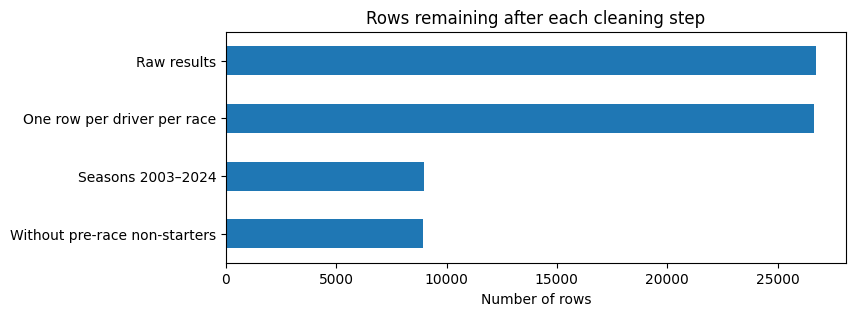

Raw results                      26759
One row per driver per race      26668
Seasons 2003–2024                 8970
Without pre-race non-starters     8934
dtype: int64


In [31]:
# Count the rows after each cleaning step, in order.
steps = pd.Series({
    'Raw results': len(raw['results']),
    'One row per driver per race': len(results_grain),
    'Seasons 2003–2024': len(window_status),
    'Without pre-race non-starters': len(model_base),
})

# Draw the row counts as a horizontal bar chart.
steps.plot(kind='barh', figsize=(8, 3))

# Put the first step at the top, so the chart reads from top to bottom.
plt.gca().invert_yaxis()

# Add a title to the chart.
plt.title('Rows remaining after each cleaning step')

# Label the x-axis.
plt.xlabel('Number of rows')

# Display the chart.
plt.show()

# Print the same counts as numbers, for the report.
print(steps)

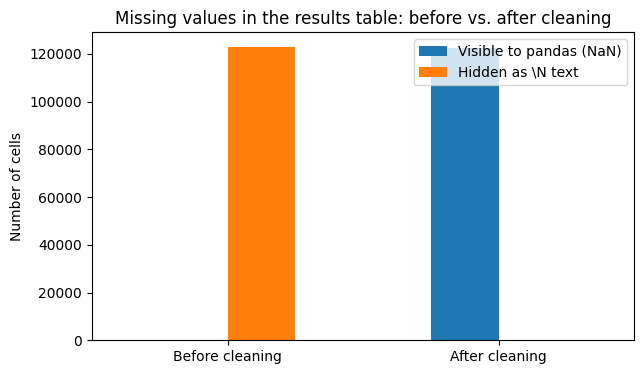

                 Visible to pandas (NaN)  Hidden as \N text
Before cleaning                        0             122887
After cleaning                    122338                  0


In [32]:
# Count the missing values pandas could see in the raw results (none, because \N was plain text).
raw_visible = raw['results'].isnull().sum().sum()

# Count the \N placeholders hidden in the raw results.
raw_hidden = (raw['results'] == '\\N').sum().sum()

# Count the real missing values in the cleaned results, now visible to pandas.
clean_visible = results_grain.isnull().sum().sum()

# Count any \N text left in the cleaned results (it should be 0).
clean_hidden = (results_grain == '\\N').sum().sum()

# Put the four numbers in a small table: rows = before/after, columns = visible/hidden.
missing_compare = pd.DataFrame({
    'Visible to pandas (NaN)': [raw_visible, clean_visible],
    'Hidden as \\N text': [raw_hidden, clean_hidden],
}, index=['Before cleaning', 'After cleaning'])

# Draw the table as a grouped bar chart.
missing_compare.plot(kind='bar', figsize=(7, 4))

# Add a title to the chart.
plt.title('Missing values in the results table: before vs. after cleaning')

# Label the y-axis.
plt.ylabel('Number of cells')

# Keep the x-axis labels horizontal so they are easy to read.
plt.xticks(rotation=0)

# Display the chart.
plt.show()

# Print the same numbers, for the report.
print(missing_compare)

The results table went from 26,759 rows to 26,668 after fixing the grain (91 duplicate rows removed), to 8,970 after keeping the 2003–2024 seasons, and to 8,934 after removing the 36 pre-race non-starters. The biggest drop comes from the season restriction, which was our choice (complete qualifying data), not from errors. Before cleaning, pandas saw 0 missing values in the results table, but X values were hidden as \N text. After cleaning, there are no \N left, and Y missing values are now visible and can be handled correctly.

## 6. Question 1 - front-row conversion by circuit, before and after 2014

front-row conversion by circuit. A front-row start means starting 1st or 2nd. For each circuit, we calculate the share of front-row starts that ended on the podium, separately for 2003–2013 and 2014–2024 (11 seasons each), and for two definitions of front row: by grid position (where the driver actually started) and by qualifying position (they can differ because of grid penalties). We use 2003–2024 because qualifying data is complete only from 2003, and we exclude pre-race non-starters, as in the modeling table.

In [33]:
# Start from the modeling base (2003–2024, no pre-race non-starters), and add each race's circuit ID.
q1 = model_base.merge(clean['races'][['raceId', 'circuitId']], on='raceId', how='left')

# Add the circuit's name, renamed to "circuit" so it is clear.
q1 = q1.merge(clean['circuits'][['circuitId', 'name']].rename(columns={'name': 'circuit'}), on='circuitId', how='left')

# Take each driver's qualifying position, renamed so it does not clash with the results "position" column.
quali_pos = clean['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})

# Check that qualifying has only one row per driver per race (otherwise the join would duplicate rows).
print('Duplicate (race, driver) pairs in qualifying:', quali_pos.duplicated(subset=['raceId', 'driverId']).sum())

# Add the qualifying position to each row.
q1 = q1.merge(quali_pos, on=['raceId', 'driverId'], how='left')

# Label each row with its era: before 2014, or from 2014 on.
q1['era'] = np.where(q1['year'] >= 2014, '2014–2024', '2003–2013')

# Mark whether the driver started on the front row (grid 1 or 2).
q1['front_row_grid'] = q1['grid'].isin([1, 2])

# Mark whether the driver qualified on the front row (qualifying position 1 or 2).
q1['front_row_quali'] = q1['quali_pos'].isin([1, 2])

# Check that the join did not add or lose rows.
print('Rows in model_base:', len(model_base), '| Rows in q1:', len(q1))

Duplicate (race, driver) pairs in qualifying: 0
Rows in model_base: 8934 | Rows in q1: 8934


In [34]:
# Count the rows by: qualified on the front row (yes/no) vs. started on the front row (yes/no).
pd.crosstab(q1['front_row_quali'], q1['front_row_grid'], rownames=['Front row by qualifying'], colnames=['Front row by grid'])

Front row by grid,False,True
Front row by qualifying,,
False,8044,36
True,38,816


Qualifying vs. grid. Of the 854 drivers who qualified on the front row (2003–2024), 38 did not start there because of grid penalties, and 36 other drivers started on the front row without qualifying there. So the two definitions disagree in about 4% of front-row slots: small but real. We use the grid as the main definition, since the question is about front-row starts, and we also show the qualifying-based result for comparison.

In [35]:
# Keep only the drivers who started on the front row (by grid).
fr = q1[q1['front_row_grid']]

# Per circuit, before 2014: the number of front-row starts, and the share that ended on the podium.
before = fr[fr['era'] == '2003–2013'].groupby('circuit')['podium'].agg(starts_before='count', rate_before='mean')

# Per circuit, from 2014 on: the same two numbers.
after = fr[fr['era'] == '2014–2024'].groupby('circuit')['podium'].agg(starts_after='count', rate_after='mean')

# Put both eras side by side, keeping only circuits used in both eras (so we can compare them).
grid_table = before.join(after, how='inner')

# Keep only circuits with at least 10 front-row starts in each era, so the rates are reliable.
grid_table = grid_table[(grid_table['starts_before'] >= 10) & (grid_table['starts_after'] >= 10)].copy()

# Rank the circuits by their conversion rate before 2014 (1 = highest).
grid_table['rank_before'] = grid_table['rate_before'].rank(ascending=False).astype(int)

# Rank the circuits by their conversion rate from 2014 on (1 = highest).
grid_table['rank_after'] = grid_table['rate_after'].rank(ascending=False).astype(int)

# Show the table, sorted by the rate from 2014 on, with the rates as percentages.
grid_table.sort_values('rate_after', ascending=False).style.format({'rate_before': '{:.0%}', 'rate_after': '{:.0%}'})

,starts_before,rate_before,starts_after,rate_after,rank_before,rank_after
circuit,,,,,,
Suzuka Circuit,18,72%,18,89%,4,1
Yas Marina Circuit,10,60%,22,86%,10,2
Circuit de Monaco,22,77%,20,85%,1,3
Circuit de Spa-Francorchamps,18,72%,22,82%,4,4
Circuit de Barcelona-Catalunya,22,68%,22,82%,6,4
Autódromo José Carlos Pace,22,59%,19,79%,12,6
Shanghai International Circuit,20,65%,14,79%,8,7
Circuit Gilles Villeneuve,20,60%,18,78%,10,8
Silverstone Circuit,22,73%,24,75%,3,9


In [36]:
# Keep only the drivers who qualified on the front row (by qualifying position).
fr_q = q1[q1['front_row_quali']]

# Per circuit, before 2014: the number of front-row qualifiers, and the share that ended on the podium.
before_q = fr_q[fr_q['era'] == '2003–2013'].groupby('circuit')['podium'].agg(starts_before='count', rate_before='mean')

# Per circuit, from 2014 on: the same two numbers.
after_q = fr_q[fr_q['era'] == '2014–2024'].groupby('circuit')['podium'].agg(starts_after='count', rate_after='mean')

# Put both eras side by side, keeping only circuits used in both eras.
quali_table = before_q.join(after_q, how='inner')

# Keep only circuits with at least 10 front-row qualifiers in each era, so the rates are reliable.
quali_table = quali_table[(quali_table['starts_before'] >= 10) & (quali_table['starts_after'] >= 10)].copy()

# Rank the circuits by their conversion rate before 2014 (1 = highest).
quali_table['rank_before'] = quali_table['rate_before'].rank(ascending=False).astype(int)

# Rank the circuits by their conversion rate from 2014 on (1 = highest).
quali_table['rank_after'] = quali_table['rate_after'].rank(ascending=False).astype(int)

# Show the table, sorted by the rate from 2014 on, with the rates as percentages.
quali_table.sort_values('rate_after', ascending=False).style.format({'rate_before': '{:.0%}', 'rate_after': '{:.0%}'})

,starts_before,rate_before,starts_after,rate_after,rank_before,rank_after
circuit,,,,,,
Suzuka Circuit,18,72%,18,89%,3,1
Circuit de Monaco,22,68%,20,85%,6,2
Circuit de Spa-Francorchamps,18,72%,22,82%,3,4
Yas Marina Circuit,10,60%,22,82%,9,4
Circuit de Barcelona-Catalunya,22,64%,22,82%,8,4
Shanghai International Circuit,20,70%,14,79%,5,6
Silverstone Circuit,22,77%,24,75%,1,7
Autodromo Nazionale di Monza,22,73%,22,73%,2,8
Circuit Gilles Villeneuve,20,60%,18,72%,9,10


In [37]:
# Describe the conditions for each group, using both qualifying and grid.
conditions = [
    q1['front_row_quali'] & q1['front_row_grid'],
    q1['front_row_quali'] & ~q1['front_row_grid'],
    ~q1['front_row_quali'] & q1['front_row_grid'],
]

# Give each condition a name, in the same order.
group_names = ['Both (qualified and started front row)', 'Penalized (qualified front row, started further back)', 'Promoted (started front row, did not qualify there)']

# Label every row with its group, or "neither" if it matches none of the conditions.
q1['front_row_group'] = np.select(conditions, group_names, default='Neither')

# For each group except "neither": the number of drivers and the share that finished on the podium.
groups = q1[q1['front_row_group'] != 'Neither'].groupby('front_row_group')['podium'].agg(drivers='count', podium_rate='mean')

# Show the result, with the podium rate as a percentage.
groups.style.format({'podium_rate': '{:.0%}'})

,drivers,podium_rate
front_row_group,,
Both (qualified and started front row),816,73%
"Penalized (qualified front row, started further back)",38,29%
"Promoted (started front row, did not qualify there)",36,64%


Qualifying and grid together. We split the front-row drivers (2003–2024) into three groups. Drivers who qualified and started on the front row reached the podium 73% of the time (816 drivers). Drivers who qualified on the front row but started further back because of a penalty reached it only 29% of the time (38 drivers). Drivers who started on the front row without qualifying there reached it 64% of the time (36 drivers). So the actual starting position matters more than qualifying speed alone: being among the two fastest was not enough without the front-row start. The two smaller groups are small, so their rates are less precise, but the gap between 73% and 29% is too large to be noise. This is not proof of cause: penalties often come from engine changes, so some penalized cars may also have had technical problems.

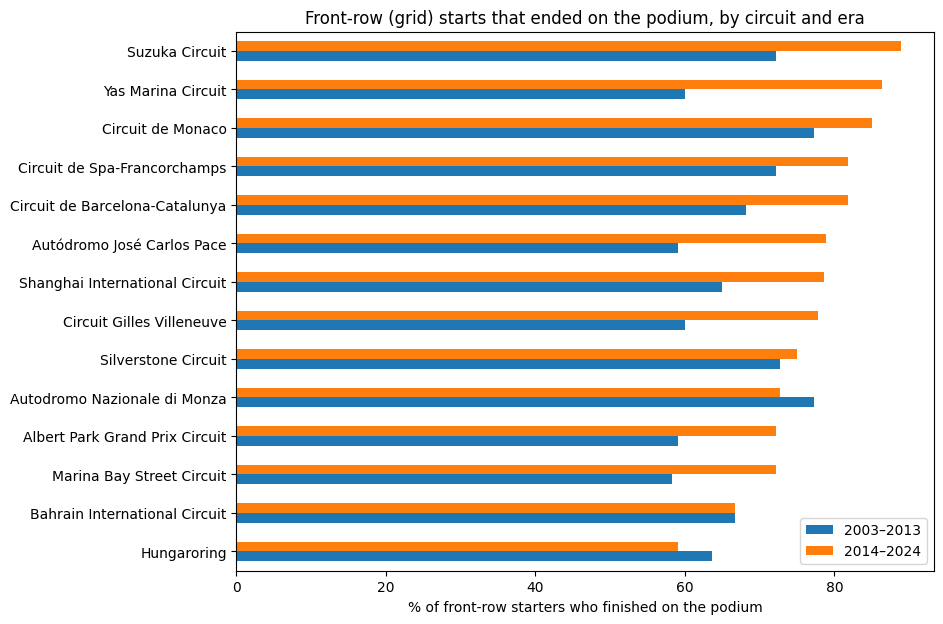

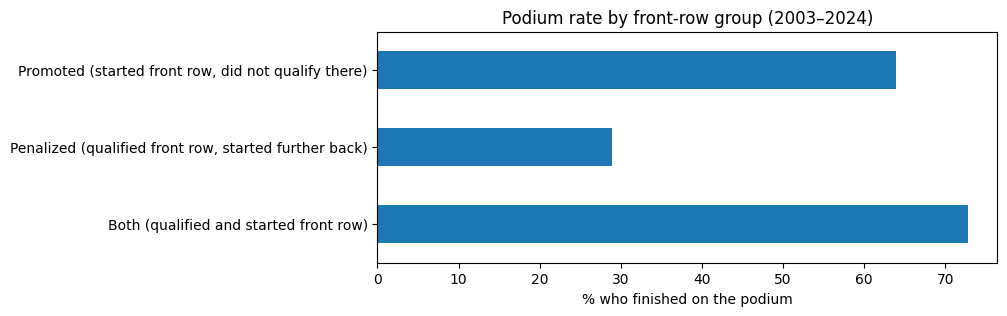

In [38]:
# Take the before and after rates per circuit (by grid), as percentages, sorted by the rate from 2014 on.
chart_data = (grid_table[['rate_before', 'rate_after']] * 100).sort_values('rate_after')

# Give the two columns clear names for the legend.
chart_data.columns = ['2003–2013', '2014–2024']

# Draw a horizontal bar chart with the two eras side by side for each circuit.
chart_data.plot(kind='barh', figsize=(9, 7))

# Add a title to the chart.
plt.title('Front-row (grid) starts that ended on the podium, by circuit and era')

# Label the x-axis.
plt.xlabel('% of front-row starters who finished on the podium')

# Remove the y-axis label (the circuit names speak for themselves).
plt.ylabel('')

# Display the chart.
plt.show()

# Take the podium rate of each group, as a percentage.
group_chart = groups['podium_rate'] * 100

# Draw a bar chart of the three groups.
group_chart.plot(kind='barh', figsize=(8, 3))

# Add a title to the chart.
plt.title('Podium rate by front-row group (2003–2024)')

# Label the x-axis.
plt.xlabel('% who finished on the podium')

# Remove the y-axis label.
plt.ylabel('')

# Display the chart.
plt.show()

Q1 answer. Using grid position (where the driver actually started) for 2003–2024, the circuits where a front-row start most often ends on the podium from 2014 on are Suzuka (89%), Yas Marina (86%), and Monaco (85%). The ranking changed after 2014: the front row became more decisive at almost every circuit (most rates rose from about 58–77% to 72–89%), Yas Marina rose from 10th to 2nd, while Monza fell from 1st to 10th and Silverstone from 3rd to 9th. Monaco stayed near the top in both eras. Each circuit has only about 18–24 front-row starts per era, so one podium changes a rate by about 5 points: small rank changes may be noise, and only large moves should be read as real.

Qualifying vs. grid. The two definitions agree for about 96% of front-row slots, and most circuit rates are similar. But at a few circuits the choice changes the ranking: for example, Monaco before 2014 is 1st by grid but 6th by qualifying. Combining both, drivers who qualified and started on the front row reached the podium 73% of the time, drivers who qualified there but started further back because of a penalty only 29%, and drivers promoted to the front row 64%. So the actual starting position matters more than qualifying speed alone.

Grain, missing data, and cutoff. Each row is one driver in one race (duplicates resolved during cleaning). We used 2003–2024 because qualifying data is complete only from then, and we excluded drivers who could not start for pre-race reasons. We only kept circuits with at least 10 front-row starts in each era. Grid and qualifying positions are both known before the race starts; the podium is the outcome we measure.

In [39]:
# Start from the modeling base, and add each race's circuit ID.
q2 = model_base.merge(clean['races'][['raceId', 'circuitId']], on='raceId', how='left')

# Add the country of each circuit.
q2 = q2.merge(clean['circuits'][['circuitId', 'country']], on='circuitId', how='left')

# Add each driver's nationality.
q2 = q2.merge(clean['drivers'][['driverId', 'nationality']], on='driverId', how='left')

# Check that the joins did not add or lose rows.
print('Rows in model_base:', len(model_base), '| Rows in q2:', len(q2))

# Show every driver nationality that appears in our seasons, in alphabetical order.
print('\nNationalities:', sorted(q2['nationality'].unique()))

# Show every circuit country that appears in our seasons, in alphabetical order.
print('\nCountries:', sorted(q2['country'].unique()))

Rows in model_base: 8934 | Rows in q2: 8934

Nationalities: ['American', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chinese', 'Colombian', 'Danish', 'Dutch', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Russian', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Venezuelan']

Countries: ['Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'Spain', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


In [40]:
# Remove extra spaces at the start or end of each nationality (fixes "Argentinian ").
q2['nationality'] = q2['nationality'].str.strip()

# Use one name for the United States, so both spellings count as the same country.
q2['country'] = q2['country'].replace({'United States': 'USA'})

# Translate each nationality into the country name used by the circuits table.
nationality_to_country = {
    'American': 'USA', 'Argentinian': 'Argentina', 'Australian': 'Australia', 'Austrian': 'Austria',
    'Belgian': 'Belgium', 'Brazilian': 'Brazil', 'British': 'UK', 'Canadian': 'Canada',
    'Chinese': 'China', 'Colombian': 'Colombia', 'Danish': 'Denmark', 'Dutch': 'Netherlands',
    'Finnish': 'Finland', 'French': 'France', 'German': 'Germany', 'Hungarian': 'Hungary',
    'Indian': 'India', 'Indonesian': 'Indonesia', 'Irish': 'Ireland', 'Italian': 'Italy',
    'Japanese': 'Japan', 'Mexican': 'Mexico', 'Monegasque': 'Monaco', 'New Zealander': 'New Zealand',
    'Polish': 'Poland', 'Portuguese': 'Portugal', 'Russian': 'Russia', 'Spanish': 'Spain',
    'Swedish': 'Sweden', 'Swiss': 'Switzerland', 'Thai': 'Thailand', 'Venezuelan': 'Venezuela',
}

# Create each driver's home country using the translation table.
q2['home_country'] = q2['nationality'].map(nationality_to_country)

# Check that every nationality was translated (this should print 0).
print('Nationalities not translated:', q2['home_country'].isnull().sum())

# Mark a row as a home race when the circuit's country is the driver's home country.
q2['home'] = q2['country'] == q2['home_country']

# Show how many home and away rows there are.
print(q2['home'].value_counts())

# Show which nationalities race at home most often.
print(q2[q2['home']]['nationality'].value_counts())

Nationalities not translated: 0
home
False    8569
True      365
Name: count, dtype: int64
nationality
German        77
British       63
Spanish       45
Italian       41
Brazilian     33
Australian    23
Japanese      17
French        13
Canadian      10
Mexican       10
Russian        8
American       7
Monegasque     6
Dutch          4
Belgian        3
Hungarian      2
Indian         2
Chinese        1
Name: count, dtype: int64


## 7. Question 2 - home advantage, controlling for starting position

what we are trying to do here is to match between teh race circut country an dthe driver nationality 

Q2: home advantage. A home race is a race at a circuit in the driver’s own country (we matched driver nationality to circuit country, for example British → UK). We compare the podium rate at home and away. Because starting position strongly affects the podium chance (Q1), we compare only drivers who started from similar grid positions: grid 1–3, 4–6, 7–10, and 11 or worse (including pit-lane starts).

In [41]:
# The simple comparison, without controlling for anything: podium rate at home vs. away.
print('Simple comparison (no control):')
print(q2.groupby('home')['podium'].agg(rows='count', podium_rate='mean'))

# Treat pit-lane starts (grid 0) as starting at the very back, for grouping only.
q2['grid_for_group'] = q2['grid'].replace(0, 99)

# Put each row into a starting-position group.
q2['grid_group'] = pd.cut(q2['grid_for_group'], bins=[0, 3, 6, 10, 100],
                          labels=['1–3', '4–6', '7–10', '11+ (incl. pit lane)'])

# In each grid group, the number of home and away rows.
counts = q2.pivot_table(index='grid_group', columns='home', values='podium', aggfunc='count', observed=True)

# In each grid group, the podium rate at home and away.
rates = q2.pivot_table(index='grid_group', columns='home', values='podium', aggfunc='mean', observed=True)

# Give the columns clear names (False = away, True = home).
counts.columns = ['Away rows', 'Home rows']
rates.columns = ['Away podium rate', 'Home podium rate']

# Put the counts and the rates side by side in one table.
v1 = pd.concat([counts, rates], axis=1)

# Show the table, with the rates as percentages.
v1.style.format({'Away podium rate': '{:.0%}', 'Home podium rate': '{:.0%}'})

Simple comparison (no control):
       rows  podium_rate
home                    
False  8569     0.143774
True    365     0.142466


,Away rows,Home rows,Away podium rate,Home podium rate
grid_group,,,,
1–3,1218,61,66%,61%
4–6,1234,48,23%,23%
7–10,1624,76,6%,3%
11+ (incl. pit lane),4493,180,1%,1%


Result (controlling for grid position). Without any control, the podium rate is the same at home (14.2%, 365 races) and away (14.4%, 8,569 races). Comparing drivers who started from similar positions, the rates are identical for grid 4–6 (23%) and 11+ (1%), and slightly lower at home for grid 1–3 (61% vs. 66%) and 7–10 (3% vs. 6%). These two differences correspond to only 2–3 podiums, because home races are rare (only 4% of all rows), so they are likely due to chance. We find no evidence of a home advantage in 2003–2024.

VERSION 2

Same-driver comparison (our extension). Even within a grid group, home drivers might be better or worse drivers on average than the away group. To remove that, we compare each driver with himself: for each driver and grid group, we compare his podium rate at home with his own podium rate away from the same grid group. We then add up, over all drivers, the actual home podiums and the podiums each driver would have scored at home if he had performed as he usually does away.

In [42]:
# For each driver, grid group, and home/away: the number of starts and the podium rate.
g = q2.groupby(['driverId', 'grid_group', 'home'], observed=True)['podium'].agg(n='count', rate='mean').reset_index()

# Keep the home side, and name its columns clearly.
home_side = g[g['home']].rename(columns={'n': 'home_starts', 'rate': 'home_rate'}).drop(columns='home')

# Keep the away side, and name its columns clearly.
away_side = g[~g['home']].rename(columns={'n': 'away_starts', 'rate': 'away_rate'}).drop(columns='home')

# Match each driver's home and away results within the same grid group (only drivers who have both).
pairs = home_side.merge(away_side, on=['driverId', 'grid_group'], how='inner')

# Show how many of the 365 home races could be matched to the same driver's away races.
print('Home races matched:', pairs['home_starts'].sum(), 'of', q2['home'].sum())

# The podiums each driver actually scored at home.
pairs['actual_home_podiums'] = pairs['home_rate'] * pairs['home_starts']

# The podiums he would have scored at home if he had done as well as he usually does away.
pairs['expected_podiums'] = pairs['away_rate'] * pairs['home_starts']

# Add everything up per grid group.
v2 = pairs.groupby('grid_group', observed=True)[['home_starts', 'actual_home_podiums', 'expected_podiums']].sum()

# Add a total row for all grid groups together.
v2.loc['All groups'] = v2.sum()

# The actual home podium rate.
v2['home_rate'] = v2['actual_home_podiums'] / v2['home_starts']

# The rate the same drivers usually have away, from the same grid group.
v2['same_drivers_away_rate'] = v2['expected_podiums'] / v2['home_starts']

# Show the table, with rounded numbers and percentages.
v2.style.format({'actual_home_podiums': '{:.0f}', 'expected_podiums': '{:.1f}',
                 'home_rate': '{:.0%}', 'same_drivers_away_rate': '{:.0%}'})

Home races matched: 363 of 365


,home_starts,actual_home_podiums,expected_podiums,home_rate,same_drivers_away_rate
grid_group,,,,,
1–3,61.000000,37,40.5,61%,66%
4–6,47.000000,11,11.0,23%,23%
7–10,76.000000,2,3.5,3%,5%
11+ (incl. pit lane),179.000000,2,2.0,1%,1%
All groups,363.000000,52,56.9,14%,16%


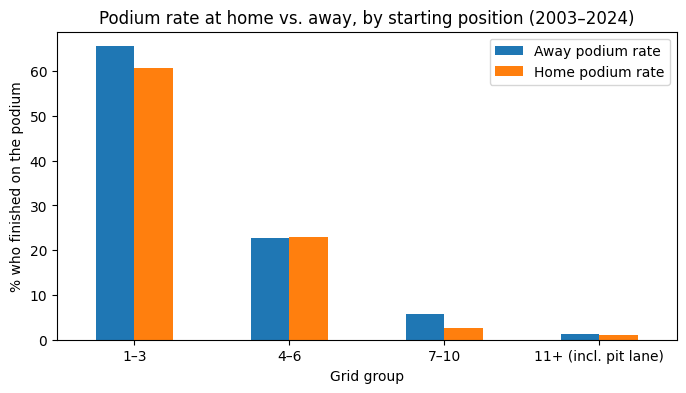

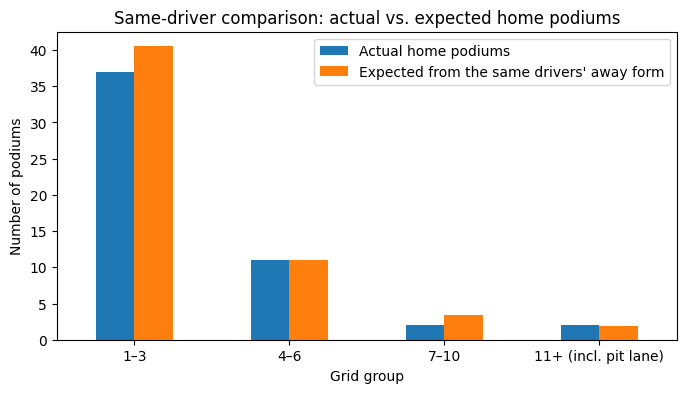

In [43]:
# Take the home and away podium rates per grid group from Version 1, as percentages.
chart_v1 = rates * 100

# Draw them as side-by-side bars for each grid group.
chart_v1.plot(kind='bar', figsize=(8, 4))

# Add a title to the chart.
plt.title('Podium rate at home vs. away, by starting position (2003–2024)')

# Label the y-axis.
plt.ylabel('% who finished on the podium')

# Label the x-axis.
plt.xlabel('Grid group')

# Keep the x-axis labels horizontal.
plt.xticks(rotation=0)

# Display the chart.
plt.show()

# Take the actual and expected home podiums per grid group from Version 2 (without the total row).
chart_v2 = v2.drop('All groups')[['actual_home_podiums', 'expected_podiums']]

# Give the columns clear names for the legend.
chart_v2.columns = ['Actual home podiums', "Expected from the same drivers' away form"]

# Draw them as side-by-side bars for each grid group.
chart_v2.plot(kind='bar', figsize=(8, 4))

# Add a title to the chart.
plt.title('Same-driver comparison: actual vs. expected home podiums')

# Label the y-axis.
plt.ylabel('Number of podiums')

# Label the x-axis.
plt.xlabel('Grid group')

# Keep the x-axis labels horizontal.
plt.xticks(rotation=0)

# Display the chart.
plt.show()

## 8. Question 3 - mechanical-retirement rate by constructor

Q3: mechanical retirements by constructor. A mechanical retirement is a race start that ended early because a part of the car failed, excluding crashes, driver errors, and regulation decisions. We use the 2014–2024 rows of the modeling base, which only contains drivers who started the race. We first list all the statuses that appear, so we can sort them into finished, mechanical, and non-mechanical groups, and we check how many starts each team has, to choose a fair minimum.

In [44]:
# Keep the rows from 2014 to 2024 (starts only, since pre-race non-starters are already removed).
q3 = model_base[model_base['year'] >= 2014].copy()

# Label each row with its era.
q3['era'] = np.where(q3['year'] >= 2022, '2022–2024', '2014–2021')

# Add the team name, renamed to "constructor" so it is clear.
q3 = q3.merge(clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor'}), on='constructorId', how='left')

# Show how many rows each era has.
print(q3['era'].value_counts())

# Let pandas show long lists in full instead of cutting them.
pd.set_option('display.max_rows', 100)

# Output 1: every status that appears in these years, from most to least common.
print('\nStatuses:')
print(q3['status'].value_counts())

# Output 2: the number of starts for each team in each era, smallest first.
print('\nStarts per team and era:')
print(q3.groupby(['era', 'constructor']).size().sort_values())

era
2014–2021    3258
2022–2024    1354
Name: count, dtype: int64

Statuses:
status
Finished            2403
+1 Lap              1178
+2 Laps              208
Collision            150
Accident              85
Engine                81
Collision damage      59
Retired               50
Brakes                49
Power Unit            42
Gearbox               42
Suspension            25
+3 Laps               24
Hydraulics            15
Electrical            14
Power loss            13
Wheel                 11
Spun off              11
Disqualified          11
Oil leak              10
Overheating            8
Water pressure         7
Puncture               7
Mechanical             7
Turbo                  6
+4 Laps                6
ERS                    5
Fuel pressure          5
Battery                5
Exhaust                5
Tyre                   4
Electronics            4
Water leak             4
Undertray              4
Front wing             3
Radiator               3
Wheel nut       

Sorting the statuses. We counted a retirement as mechanical only when the status clearly names a car part that failed (for example Engine, Gearbox, Brakes, Hydraulics, Power Unit, Suspension). We did not count crashes (Collision, Accident, Damage, Debris), driver causes (Spun off, Illness), rule decisions (Disqualified, Excluded), or team and operational causes where no part failed by itself (Wheel and Wheel nut, often pit-stop errors; front wing, rear wing, and undertray, usually contact damage; Puncture, Tyre, Vibrations; Out of fuel). “Retired” (50 rows) gives no reason, so we did not count it as mechanical, but these cars still count as race starts. Every team in 2014–2024 has at least about one full season of starts (31 or more), so we kept all teams and show the number of starts next to each rate.

In [45]:
# List the statuses that clearly mean a part of the car failed.
mechanical_statuses = [
    'Engine', 'Power Unit', 'Gearbox', 'Transmission', 'Clutch', 'Driveshaft', 'Drivetrain', 'Differential',
    'Brakes', 'Brake duct', 'Hydraulics', 'Electrical', 'Electronics', 'Battery', 'ERS', 'Turbo',
    'Power loss', 'Oil leak', 'Oil pressure', 'Water pressure', 'Water leak', 'Water pump', 'Radiator',
    'Cooling system', 'Overheating', 'Fuel pressure', 'Fuel leak', 'Fuel pump', 'Fuel system', 'Exhaust',
    'Spark plugs', 'Throttle', 'Steering', 'Suspension', 'Seat', 'Mechanical', 'Technical',
]

# Mark the rows where the driver finished the race ("Finished" or "+N Laps").
finished = (q3['status'] == 'Finished') | q3['status'].str.startswith('+')

# Mark the rows where a part of the car failed.
mechanical = q3['status'].isin(mechanical_statuses)

# Give every row one outcome: finished, mechanical retirement, or other retirement.
q3['outcome'] = np.select([finished, mechanical], ['Finished', 'Mechanical'], default='Other retirement')

# Check which statuses ended up as "other retirement", to make sure nothing was sorted by mistake.
print('Statuses counted as other (non-mechanical) retirements:')
print(q3.loc[q3['outcome'] == 'Other retirement', 'status'].value_counts())

# Make a 1/0 column: 1 if the race ended with a mechanical retirement.
q3['mech_retirement'] = (q3['outcome'] == 'Mechanical').astype(int)

# For each era and team: the number of starts, mechanical retirements, and the mechanical-retirement rate.
mech_rates = q3.groupby(['era', 'constructor'])['mech_retirement'].agg(starts='count', mechanical='sum', rate='mean').reset_index()

# Show the teams of 2014–2021, highest rate first.
print('\n2014–2021:')
print(mech_rates[mech_rates['era'] == '2014–2021'].sort_values('rate', ascending=False).to_string(index=False))

# Show the teams of 2022–2024, highest rate first.
print('\n2022–2024:')
print(mech_rates[mech_rates['era'] == '2022–2024'].sort_values('rate', ascending=False).to_string(index=False))

Statuses counted as other (non-mechanical) retirements:
status
Collision           150
Accident             85
Collision damage     59
Retired              50
Disqualified         11
Wheel                11
Spun off             11
Puncture              7
Tyre                  4
Undertray             4
Rear wing             3
Illness               3
Front wing            3
Wheel nut             3
Damage                2
Vibrations            2
Excluded              1
Debris                1
Out of fuel           1
Name: count, dtype: int64

2014–2021:
      era    constructor  starts  mechanical     rate
2014–2021       Caterham      34           8 0.235294
2014–2021       Lotus F1      75          13 0.173333
2014–2021     Toro Rosso     242          39 0.161157
2014–2021        McLaren     318          43 0.135220
2014–2021        Renault     200          27 0.135000
2014–2021         Sauber     200          22 0.110000
2014–2021       Red Bull     319          34 0.106583
2014–2021  

Q3 answer. In 2014–2021, the constructors with the highest mechanical-retirement rate were Caterham (24%, but only 34 starts in one season), Lotus F1 (17%), Toro Rosso (16%, 242 starts), and McLaren (14%, 318 starts). The most reliable full-time teams were Mercedes (4%) and Ferrari (5%). In 2022–2024, the highest rates were Alfa Romeo (13%) and Alpine (11%), while Red Bull and McLaren were among the most reliable (4%). Cars became more reliable overall: about 9% of starts ended with a mechanical failure in 2014–2021, compared with about 6% in 2022–2024. The ranking also changed: McLaren went from one of the least reliable teams to one of the most reliable, while Alfa Romeo went from one of the most reliable to the least reliable.

Grain, missing data, and cutoff. Each row is one driver’s race start (2014–2024), so the rate is mechanical retirements divided by starts. Drivers who did not start for pre-race reasons are excluded. We counted only statuses that clearly name a failed car part; crashes, driver causes, rule decisions, team or operational causes, and the 50 “Retired” rows with no reason were not counted as mechanical. Teams with only one season of starts (31–48) have less precise rates. Teams that changed names are counted separately, since each name has its own constructor ID. Q3 is a descriptive analysis of race outcomes, so it uses post-race information (status) by design; status is never used as a model feature.

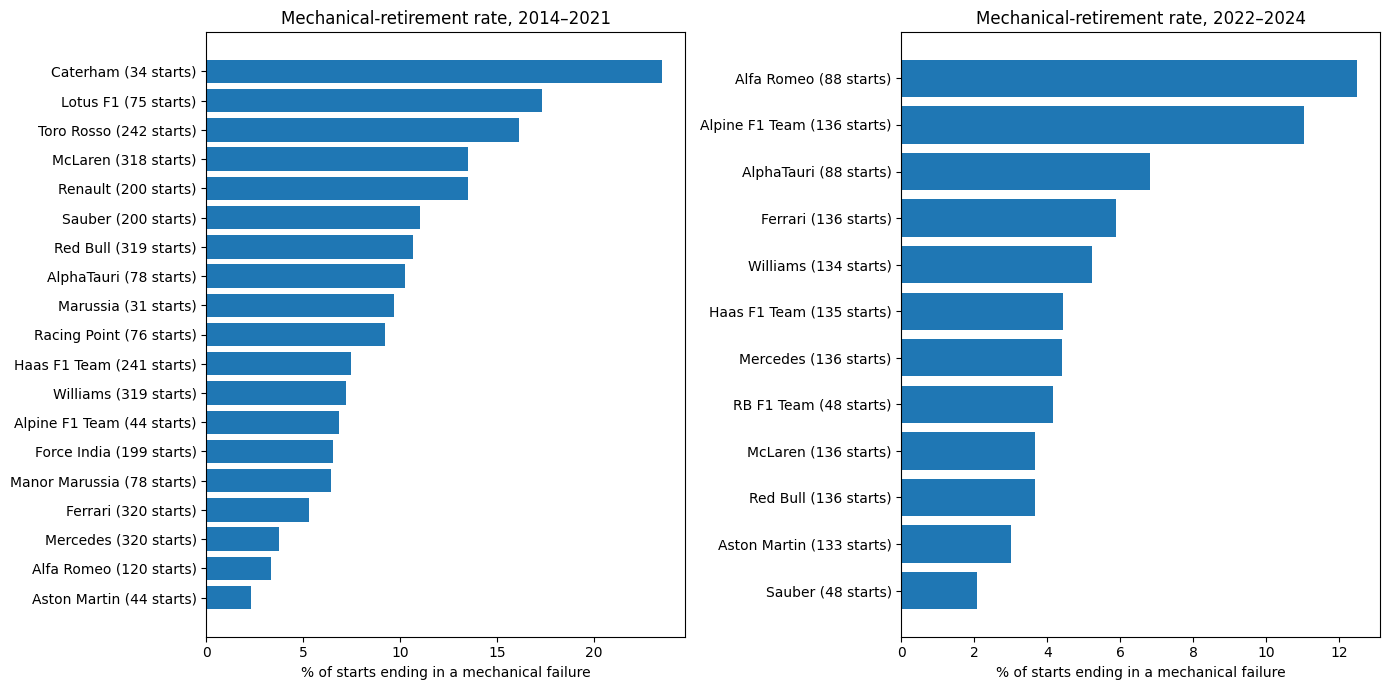

In [46]:
# Create two charts side by side, one for each era.
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Go through the two eras, one chart each.
for ax, era in zip(axes, ['2014–2021', '2022–2024']):

    # Take this era's teams, sorted so the highest rate appears at the top of the chart.
    era_data = mech_rates[mech_rates['era'] == era].sort_values('rate')

    # Label each team with its number of starts, so small samples are visible.
    labels = era_data['constructor'] + ' (' + era_data['starts'].astype(str) + ' starts)'

    # Draw one horizontal bar per team, with the rate as a percentage.
    ax.barh(labels, era_data['rate'] * 100)

    # Add a title for this era.
    ax.set_title(f'Mechanical-retirement rate, {era}')

    # Label the x-axis.
    ax.set_xlabel('% of starts ending in a mechanical failure')

# Space the two charts out so the labels do not overlap.
plt.tight_layout()

# Display the charts.
plt.show()

## 9. Feature engineering

Feature engineering, step 1: race history in time order. Form features use a driver’s or team’s previous races, so we first build one table with every race start in F1 history (all seasons, so the first races of 2003 still have earlier history), without pre-race non-starters, and sort it by race date. All features are calculated on this full history first; only afterwards do we keep the 2003–2024 rows and remove the 22 rows without a qualifying record.

In [47]:
# Start from the cleaned results (all seasons) and add each race's year, round, and date.
history = results_grain.merge(clean['races'][['raceId', 'year', 'round', 'date']], on='raceId', how='left')

# Add the status text, so we can find the pre-race non-starters.
history = history.merge(clean['status'], on='statusId', how='left')

# Remove the pre-race non-starters (withdrew, did not qualify, etc.), since they did not start the race.
history = history[~history['status'].isin(pre_race_non_start)].copy()

# Mark each row as a podium (1) or not (0).
history['podium'] = (history['positionOrder'] <= 3).astype(int)

# Sort all rows by race date (and by race ID if two races share a date), so "previous" means earlier in time.
history = history.sort_values(['date', 'raceId']).reset_index(drop=True)

# Check the size and the time range of the history table.
print('Rows:', len(history), '| From', history['date'].min().date(), 'to', history['date'].max().date())

# Check the order on one driver: Lewis Hamilton (driverId 1), his first 5 races.
history[history['driverId'] == 1][['date', 'year', 'round', 'raceId', 'grid', 'positionOrder', 'podium']].head()

Rows: 25045 | From 1950-05-13 to 2024-12-08


,date,year,round,raceId,grid,positionOrder,podium
17551,2007-03-18,2007,1,36,4,3,1
17572,2007-04-08,2007,2,37,4,2,1
17594,2007-04-15,2007,3,38,2,2,1
17616,2007-05-13,2007,4,39,4,2,1
17638,2007-05-27,2007,5,40,2,2,1


In [48]:
# Start from the cleaned results (all seasons) and add each race's year, round, and date.
history = results_grain.merge(clean['races'][['raceId', 'year', 'round', 'date']], on='raceId', how='left')

# Add the status text, so we can find the pre-race non-starters.
history = history.merge(clean['status'], on='statusId', how='left')

# Remove the pre-race non-starters (withdrew, did not qualify, etc.), since they did not start the race.
history = history[~history['status'].isin(pre_race_non_start)].copy()

# Mark each row as a podium (1) or not (0).
history['podium'] = (history['positionOrder'] <= 3).astype(int)

# Sort all rows by race date (and by race ID if two races share a date), so "previous" means earlier in time.
history = history.sort_values(['date', 'raceId']).reset_index(drop=True)

# Check the size and the time range of the history table.
print('Rows:', len(history), '| From', history['date'].min().date(), 'to', history['date'].max().date())

# Check the order on one driver: Lewis Hamilton (driverId 1), his first 5 races.
history[history['driverId'] == 1][['date', 'year', 'round', 'raceId', 'grid', 'positionOrder', 'podium']].head()

Rows: 25045 | From 1950-05-13 to 2024-12-08


,date,year,round,raceId,grid,positionOrder,podium
17551,2007-03-18,2007,1,36,4,3,1
17572,2007-04-08,2007,2,37,4,2,1
17594,2007-04-15,2007,3,38,2,2,1
17616,2007-05-13,2007,4,39,4,2,1
17638,2007-05-27,2007,5,40,2,2,1


Feature engineering, step 2: driver form. For each race start, we calculate the driver’s number of podiums and his average finishing position over his previous 5 race starts. To make this leakage-safe, the values are shifted by one race, so each row only uses races that happened before it, never the race itself. If a driver has fewer than 5 previous races, we use the ones he has. For a driver’s very first race there is no history, so these values are empty; we also store the number of previous races, so we can see how many rows this affects.

In [49]:
# Group the history by driver, so each calculation only looks at that driver's own races.
by_driver = history.groupby('driverId')

# Podiums in the previous 5 races: shift by one race (never the race itself), then add up the last 5 values.
history['driver_podiums_last5'] = by_driver['podium'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())

# Average finishing position in the previous 5 races, calculated the same way.
history['driver_avg_finish_last5'] = by_driver['positionOrder'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# Number of races the driver started before this one (0 means this is his first race).
history['driver_prev_races'] = by_driver.cumcount()

# Check on Hamilton's first 7 races: the form values should only use the races above each row.
history[history['driverId'] == 1][['date', 'positionOrder', 'podium', 'driver_prev_races', 'driver_podiums_last5', 'driver_avg_finish_last5']].head(7)

,date,positionOrder,podium,driver_prev_races,driver_podiums_last5,driver_avg_finish_last5
17551,2007-03-18,3,1,0,NaN,NaN
17572,2007-04-08,2,1,1,1.0,3.000000
17594,2007-04-15,2,1,2,2.0,2.500000
17616,2007-05-13,2,1,3,3.0,2.333333
17638,2007-05-27,2,1,4,4.0,2.250000
17659,2007-06-10,1,1,5,5.0,2.200000
17681,2007-06-17,1,1,6,5.0,1.800000


In [50]:
# All the statuses we already sorted in Q3: the mechanical ones and the other (non-mechanical) ones.
known_statuses = set(mechanical_statuses) | set(q3['status'].unique())

# Take the race starts from 2000 to 2013, which the team features may look back at.
older = history[(history['year'] >= 2000) & (history['year'] <= 2013)]

# Show the statuses from those years that are not sorted yet, with their counts.
print(older.loc[~older['status'].isin(known_statuses), 'status'].value_counts())

status
Alternator          4
Pneumatics          4
Halfshaft           3
+11 Laps            3
Wheel rim           3
Injured             3
Safety concerns     2
+10 Laps            2
Fuel                2
Broken wing         2
Safety              2
Fuel rig            2
Heat shield fire    2
Track rod           2
+9 Laps             2
Not restarted       1
Stalled             1
Chassis             1
Crankshaft          1
Handling            1
Not classified      1
Launch control      1
Oil line            1
Ignition            1
+12 Laps            1
Engine fire         1
Fire                1
+26 Laps            1
Tyre puncture       1
Refuelling          1
+17 Laps            1
Driver Seat         1
+42 Laps            1
Engine misfire      1
+14 Laps            1
Name: count, dtype: int64


In [51]:
# Add the older mechanical statuses (from 2000–2013) to the mechanical list, so team reliability counts every part failure.
mechanical_statuses_all = mechanical_statuses + [
    'Alternator', 'Pneumatics', 'Halfshaft', 'Track rod', 'Chassis', 'Crankshaft', 'Launch control',
    'Oil line', 'Ignition', 'Engine fire', 'Engine misfire', 'Heat shield fire', 'Driver Seat',
]

# Mark every race start in the history as a mechanical retirement (1) or not (0).
history['mech_retirement'] = history['status'].isin(mechanical_statuses_all).astype(int)

# Check: the share of mechanical retirements per decade, to see that the numbers look sensible.
print(history.groupby(history['year'] // 10 * 10)['mech_retirement'].mean().round(3))

year
1950    0.342
1960    0.377
1970    0.299
1980    0.359
1990    0.291
2000    0.181
2010    0.095
2020    0.058
Name: mech_retirement, dtype: float64


checking eeach decade teh % o f the failures the mechan failures 

In [52]:
# Combine each team's cars into one row per race: podiums, starts, and mechanical retirements.
team_race = history.groupby(['constructorId', 'raceId', 'date'], as_index=False).agg(
    team_podiums=('podium', 'sum'), team_starts=('podium', 'count'), team_mech=('mech_retirement', 'sum'))

# Sort the team rows by race date, so "previous races" means earlier in time.
team_race = team_race.sort_values(['date', 'raceId'])

# Group by team, so each calculation only looks at that team's own races.
by_team = team_race.groupby('constructorId')

# Team podiums in the previous 5 races: shift by one race, then add up the last 5.
team_race['team_podiums_last5'] = by_team['team_podiums'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())

# Mechanical retirements in the previous 10 races, calculated the same way.
mech_last10 = by_team['team_mech'].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())

# Starts in the previous 10 races, calculated the same way.
starts_last10 = by_team['team_starts'].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())

# Share of the team's recent starts that ended with a mechanical failure.
team_race['team_mech_rate_last10'] = mech_last10 / starts_last10

# Remember the number of rows before joining, to check that the join adds no rows.
rows_before = len(history)

# Copy each team's values onto every driver row of that team in that race.
history = history.merge(team_race[['constructorId', 'raceId', 'team_podiums_last5', 'team_mech_rate_last10']],
                        on=['constructorId', 'raceId'], how='left')

# Check that the number of rows did not change.
print('Rows before:', rows_before, '| after:', len(history))

# Check on Mercedes (constructorId 131), its first 7 races: values should only use earlier races.
team_race[team_race['constructorId'] == 131][['date', 'team_podiums', 'team_mech', 'team_podiums_last5', 'team_mech_rate_last10']].head(7)

Rows before: 25045 | after: 25045


,date,team_podiums,team_mech,team_podiums_last5,team_mech_rate_last10
10686,1954-07-04,2,1,NaN,NaN
10687,1954-07-17,0,0,2.0,0.333333
10688,1954-08-01,1,1,2.0,0.200000
10689,1954-08-22,2,1,3.0,0.222222
10690,1954-09-05,1,0,5.0,0.250000
10691,1954-10-24,1,0,6.0,0.200000
10680,1955-01-16,1,1,5.0,0.166667


Feature engineering, step 3: team form and team reliability. The car matters most in F1, and Q3 showed that reliability differs a lot between teams. For each team and race, we first combine both cars into one row (podiums, starts, and mechanical retirements). Then, for each race, we calculate the team’s podiums in its previous 5 races and the share of its starts that ended with a mechanical failure in its previous 10 races (more races, because failures are rarer). As before, values are shifted by one race so only earlier races are used. Each driver’s row then gets his team’s values for that race.

In [53]:
# Days since each driver's previous race (the history is sorted by date).
driver_gap_days = history.groupby('driverId')['date'].diff().dt.days

# Count the driver comebacks in 2003–2024 after more than 1 year, and after more than 2 years.
recent = history['year'] >= 2003
print('Driver comebacks after more than 1 year:', ((driver_gap_days > 365) & recent).sum())
print('Driver comebacks after more than 2 years:', ((driver_gap_days > 730) & recent).sum())

Driver comebacks after more than 1 year: 39
Driver comebacks after more than 2 years: 17


In [54]:
# Days since each team's previous race (team_race is sorted by date).
team_gap_days = team_race.groupby('constructorId')['date'].diff().dt.days

# Keep only team races from 2003 onward.
recent_team = team_race['date'].dt.year >= 2003

# Count the team comebacks in 2003–2024 after more than 1 year, and after more than 2 years.
print('Team comebacks after more than 1 year:', ((team_gap_days > 365) & recent_team).sum())
print('Team comebacks after more than 2 years:', ((team_gap_days > 730) & recent_team).sum())

# Show which teams came back, when, and after how many days away.
comebacks = team_race.loc[(team_gap_days > 365) & recent_team, ['constructorId', 'date']].copy()
comebacks['days_away'] = team_gap_days[(team_gap_days > 365) & recent_team]
comebacks.merge(clean['constructors'][['constructorId', 'name']], on='constructorId')

Team comebacks after more than 1 year: 7
Team comebacks after more than 2 years: 7


,constructorId,date,days_away,name
0,11,2006-03-12,13643.0,Honda
1,15,2010-03-14,1610.0,Sauber
2,131,2010-03-14,19908.0,Mercedes
3,4,2016-03-20,1575.0,Renault
4,51,2019-03-17,12187.0,Alfa Romeo
5,117,2021-03-28,22170.0,Aston Martin
6,15,2024-03-02,1924.0,Sauber


Feature engineering, step 3c: long breaks. Some teams and drivers stopped racing for years and then came back (for example, Mercedes raced in 1954–1955 and returned in 2010 with the same constructor ID). Their “previous races” would then come from a very different period. So we split each driver’s and each team’s history into periods: a new period starts after a break of more than two years (730 days), and form features only use races from the same period. A driver who missed only one season keeps his previous form. In 2003–2024, this rule affects 17 driver comebacks and 7 team comebacks (all teams were away for more than 4 years).

In [55]:
# Remove the form columns calculated before, so we can recalculate them with the long-break rule.
history = history.drop(columns=['driver_prev_races', 'driver_podiums_last5', 'driver_avg_finish_last5',
                                'team_podiums_last5', 'team_mech_rate_last10'])

# Make sure the history is still sorted by race date.
history = history.sort_values(['date', 'raceId']).reset_index(drop=True)

# For each row, count the days since the same driver's previous race.
driver_gap_days = history.groupby('driverId')['date'].diff().dt.days

# A new driver period starts after more than 730 days (2 years); count the periods for each driver.
history['driver_period'] = (driver_gap_days > 730).groupby(history['driverId']).cumsum()

# Group by driver and period, so form only uses races from the same period.
by_driver = history.groupby(['driverId', 'driver_period'])

# Podiums in the previous 5 races of the same period (shifted, so never the race itself).
history['driver_podiums_last5'] = by_driver['podium'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())

# Average finishing position in the previous 5 races of the same period.
history['driver_avg_finish_last5'] = by_driver['positionOrder'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# Number of races before this one in the same period (0 = first race, or first race after a long break).
history['driver_prev_races'] = by_driver.cumcount()

# Combine each team's cars into one row per race: podiums, starts, and mechanical retirements.
team_race = history.groupby(['constructorId', 'raceId', 'date'], as_index=False).agg(
    team_podiums=('podium', 'sum'), team_starts=('podium', 'count'), team_mech=('mech_retirement', 'sum'))

# Sort the team rows by race date.
team_race = team_race.sort_values(['date', 'raceId'])

# For each team row, count the days since the team's previous race.
team_gap_days = team_race.groupby('constructorId')['date'].diff().dt.days

# A new team period starts after more than 730 days (2 years).
team_race['team_period'] = (team_gap_days > 730).groupby(team_race['constructorId']).cumsum()

# Group by team and period.
by_team = team_race.groupby(['constructorId', 'team_period'])

# Team podiums in the previous 5 races of the same period.
team_race['team_podiums_last5'] = by_team['team_podiums'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())

# Mechanical retirements in the previous 10 races of the same period.
mech_last10 = by_team['team_mech'].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())

# Starts in the previous 10 races of the same period.
starts_last10 = by_team['team_starts'].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())

# Share of the team's recent starts that ended with a mechanical failure.
team_race['team_mech_rate_last10'] = mech_last10 / starts_last10

# Copy each team's values onto every driver row of that team in that race.
history = history.merge(team_race[['constructorId', 'raceId', 'team_podiums_last5', 'team_mech_rate_last10']],
                        on=['constructorId', 'raceId'], how='left')

# Check: Mercedes' first 3 races of 2010 should start with empty team form (a new period).
team_race[(team_race['constructorId'] == 131) & (team_race['date'].dt.year == 2010)][['date', 'team_period', 'team_podiums', 'team_podiums_last5']].head(3)

,date,team_period,team_podiums,team_podiums_last5
10661,2010-03-14,1,0,NaN
10662,2010-03-28,1,0,0.0
10663,2010-04-04,1,1,0.0


In [56]:
# Choose the columns we want to see: who, which race, the start, the result, and the features we built.
cols_to_show = ['year', 'round', 'driverId', 'constructorId', 'grid', 'positionOrder', 'podium',
                'driver_prev_races', 'driver_podiums_last5', 'driver_avg_finish_last5',
                'team_podiums_last5', 'team_mech_rate_last10']

# Show the size of the history table (rows, columns).
print('History table size:', history.shape)

# Show one race: the first race of 2010, with the drivers ordered by their finishing position.
history[(history['year'] == 2010) & (history['round'] == 1)][cols_to_show].sort_values('positionOrder')

History table size: (25045, 30)


,year,round,driverId,constructorId,grid,positionOrder,podium,driver_prev_races,driver_podiums_last5,driver_avg_finish_last5,team_podiums_last5,team_mech_rate_last10
18630,2010,1,4,6,3,1,1,139,1.0,10.4,1.0,0.052632
18631,2010,1,13,6,2,2,1,114,1.0,4.6,1.0,0.052632
18632,2010,1,1,1,4,3,1,52,3.0,7.6,3.0,0.050000
18633,2010,1,20,9,1,4,0,43,2.0,3.6,4.0,0.150000
18634,2010,1,3,131,5,5,0,70,0.0,11.4,NaN,NaN
18635,2010,1,30,131,7,6,0,0,NaN,NaN,NaN,NaN
18636,2010,1,18,1,8,7,0,171,2.0,4.6,3.0,0.050000
18637,2010,1,17,9,6,8,0,139,2.0,11.4,4.0,0.150000
18638,2010,1,24,10,12,9,0,44,0.0,14.4,0.0,0.100000
18639,2010,1,22,3,11,10,0,287,1.0,5.2,0.0,0.050000


Feature engineering, step 3c: long breaks. Some teams and drivers stopped racing for years and then came back. For teams, we start the history over after a break of more than four years: for example, Mercedes (1954–1955, back in 2010) and Aston Martin (back in 2021 after about 60 years) returned as completely different organizations, so their old results say nothing about the new team. In 2003–2024, the shortest team absence was about 4.3 years, so 7 teams are affected. For drivers, we keep the whole history, since it is still the same person, but we add a feature days_since_last_race, so the model can see when a driver’s recent form comes from races long ago (for example, Michael Schumacher’s return in 2010 after three years away).

In [57]:
# Remove any form columns calculated before, so this cell gives the same result every time it runs.
history = history.drop(columns=['driver_prev_races', 'driver_podiums_last5', 'driver_avg_finish_last5',
                                'days_since_last_race', 'driver_period', 'team_podiums_last5',
                                'team_mech_rate_last10', 'driver_career_races', 'driver_career_podium_rate'],
                       errors='ignore')

# Make sure the history is sorted by race date, so "previous" means earlier in time.
history = history.sort_values(['date', 'raceId']).reset_index(drop=True)

# ---------------- DRIVER FEATURES (whole career, never reset) ----------------

# Group by driver, so each calculation only looks at that driver's own races.
by_driver = history.groupby('driverId')

# Podiums in the previous 5 races (shifted, so never the race itself).
history['driver_podiums_last5'] = by_driver['podium'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())

# Average finishing position in the previous 5 races.
history['driver_avg_finish_last5'] = by_driver['positionOrder'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

# Number of races before this one in his whole career (0 = his first race ever).
history['driver_prev_races'] = by_driver.cumcount()

# Days since his previous race, so the model can see when his recent form is old (empty for his first race).
history['days_since_last_race'] = by_driver['date'].diff().dt.days

# ---------------- TEAM FEATURES (history starts over after more than 4 years away) ----------------

# Combine each team's cars into one row per race: podiums, starts, and mechanical retirements.
team_race = history.groupby(['constructorId', 'raceId', 'date'], as_index=False).agg(
    team_podiums=('podium', 'sum'), team_starts=('podium', 'count'), team_mech=('mech_retirement', 'sum'))

# Sort the team rows by race date.
team_race = team_race.sort_values(['date', 'raceId'])

# For each team row, count the days since the team's previous race.
team_gap_days = team_race.groupby('constructorId')['date'].diff().dt.days

# A new team period starts after more than 1,461 days (4 years) without racing.
team_race['team_period'] = (team_gap_days > 1461).groupby(team_race['constructorId']).cumsum()

# Group by team and period, so team form only uses races from the same period.
by_team = team_race.groupby(['constructorId', 'team_period'])

# Team podiums in the previous 5 races of the same period.
team_race['team_podiums_last5'] = by_team['team_podiums'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum())

# Mechanical retirements in the previous 10 races of the same period.
mech_last10 = by_team['team_mech'].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())

# Starts in the previous 10 races of the same period.
starts_last10 = by_team['team_starts'].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())

# Share of the team's recent starts that ended with a mechanical failure.
team_race['team_mech_rate_last10'] = mech_last10 / starts_last10

# Remember the number of rows before joining, to check that the join adds no rows.
rows_before = len(history)

# Copy each team's values onto every driver row of that team in that race.
history = history.merge(team_race[['constructorId', 'raceId', 'team_podiums_last5', 'team_mech_rate_last10']],
                        on=['constructorId', 'raceId'], how='left')

# ---------------- CHECKS ----------------

# Check that the number of rows did not change.
print('Rows before:', rows_before, '| after:', len(history))

# Check how many team comebacks after more than 4 years happen in 2003–2024 (expected: 7).
print('Team comebacks in 2003–2024:', ((team_gap_days > 1461) & (team_race['date'].dt.year >= 2003)).sum())

# Check on Schumacher (driverId 30) around his 2010 comeback: his career count continues, and the gap shows the break.
print(history[history['driverId'] == 30][['date', 'driver_prev_races', 'driver_podiums_last5', 'days_since_last_race']].iloc[247:252])

# Check on Mercedes (constructorId 131) in 2010: its team form starts empty, since it is a new period.
team_race[(team_race['constructorId'] == 131) & (team_race['date'].dt.year == 2010)][['date', 'team_period', 'team_podiums', 'team_podiums_last5']].head(3)

Rows before: 25045 | after: 25045
Team comebacks in 2003–2024: 7
            date  driver_prev_races  driver_podiums_last5  \
17483 2006-10-01                247                   4.0   
17524 2006-10-08                248                   4.0   
17530 2006-10-22                249                   3.0   
18635 2010-03-14                250                   3.0   
18663 2010-03-28                251                   2.0   

       days_since_last_race  
17483                  21.0  
17524                   7.0  
17530                  14.0  
18635                1239.0  
18663                  14.0  


,date,team_period,team_podiums,team_podiums_last5
10661,2010-03-14,1,0,NaN
10662,2010-03-28,1,0,0.0
10663,2010-04-04,1,1,0.0


Feature engineering, step 4: championship rank before the race. The championship rank summarises the whole season so far, for the driver and for his team. The standings tables store the rank after each race, so we shift by one race: each race gets the rank from the previous race, which is known before it starts. For the first race of a season, this gives the final rank of the previous season, the latest standings known before the race. We use the rank instead of the points, because the points system changed in 2010 (10 points for a win before, 25 after), while a rank means the same thing in every year. For teams, as with team form, we set the rank to empty if the team’s previous standings are from more than four years earlier.

In [58]:
# ---------------- DRIVER CHAMPIONSHIP RANK ----------------

# Take each driver's championship rank after each race, and add the race date.
ds = clean['driver_standings'][['raceId', 'driverId', 'position']].merge(clean['races'][['raceId', 'date']], on='raceId')

# Check that each driver has only one standings row per race (otherwise the join would duplicate rows).
print('Duplicate (race, driver) rows in driver standings:', ds.duplicated(subset=['raceId', 'driverId']).sum())

# Sort the standings by race date.
ds = ds.sort_values(['date', 'raceId'])

# For each driver, take the rank from his previous standings row: the rank just before this race.
ds['driver_champ_rank_before'] = ds.groupby('driverId')['position'].shift(1)

# ---------------- TEAM CHAMPIONSHIP RANK ----------------

# Take each team's championship rank after each race, and add the race date.
cs = clean['constructor_standings'][['raceId', 'constructorId', 'position']].merge(clean['races'][['raceId', 'date']], on='raceId')

# Check that each team has only one standings row per race.
print('Duplicate (race, team) rows in team standings:', cs.duplicated(subset=['raceId', 'constructorId']).sum())

# Sort the standings by race date.
cs = cs.sort_values(['date', 'raceId'])

# For each team, take the rank from its previous standings row: the rank just before this race.
cs['team_champ_rank_before'] = cs.groupby('constructorId')['position'].shift(1)

# For each team, take the date of its previous standings row.
cs['prev_date'] = cs.groupby('constructorId')['date'].shift(1)

# If the previous standings are from more than 4 years earlier, set the rank to empty (same rule as team form).
cs.loc[(cs['date'] - cs['prev_date']).dt.days > 1461, 'team_champ_rank_before'] = np.nan

# ---------------- JOIN ONTO THE HISTORY ----------------

# Remove these columns if they already exist, so this cell gives the same result every time it runs.
history = history.drop(columns=['driver_champ_rank_before', 'team_champ_rank_before'], errors='ignore')

# Remember the number of rows before joining.
rows_before = len(history)

# Add each driver's rank before the race.
history = history.merge(ds[['raceId', 'driverId', 'driver_champ_rank_before']], on=['raceId', 'driverId'], how='left')

# Add each team's rank before the race.
history = history.merge(cs[['raceId', 'constructorId', 'team_champ_rank_before']], on=['raceId', 'constructorId'], how='left')

# Check that the number of rows did not change.
print('Rows before:', rows_before, '| after:', len(history))

# ---------------- CHECK ON A REAL EXAMPLE ----------------

# Take Hamilton (driverId 1) in 2019 and 2020, and add his rank AFTER each race, only for this check.
check = history[(history['driverId'] == 1) & (history['year'].isin([2019, 2020]))].merge(
    ds[['raceId', 'driverId', 'position']].rename(columns={'position': 'rank_after_this_race'}), on=['raceId', 'driverId'])

# Show the end of 2019 and the start of 2020: the rank before each race should equal the rank after the previous one.
check[['year', 'round', 'positionOrder', 'driver_champ_rank_before', 'rank_after_this_race']].iloc[18:24]

Duplicate (race, driver) rows in driver standings: 0
Duplicate (race, team) rows in team standings: 0
Rows before: 25045 | after: 25045


,year,round,positionOrder,driver_champ_rank_before,rank_after_this_race
18,2019,19,2,1.0,1
19,2019,20,7,1.0,1
20,2019,21,1,1.0,1
21,2020,1,4,1.0,4
22,2020,2,1,4.0,2
23,2020,3,1,2.0,1


In [59]:
# Check that the "rank after" column is NOT in the history table (this should print False).
print('rank_after_this_race' in history.columns)

False


Feature engineering, step 5: qualifying. Q1 showed that qualifying speed adds information beyond the grid position. We add two features: the qualifying position, and the gap to pole position, as a percentage of the pole lap time (so tracks with different lap lengths are comparable). For each driver, we use his best lap time among the qualifying parts he drove (Q1, Q2, Q3). Qualifying happens before the race and belongs to the same race weekend, so both features are known before the race starts.

In [60]:
# Take each driver's qualifying position and his lap times (in seconds) for each qualifying part.
q = clean['qualifying'][['raceId', 'driverId', 'position', 'q1_sec', 'q2_sec', 'q3_sec']].copy()

# Rename the qualifying position, so it does not clash with the results "position" column.
q = q.rename(columns={'position': 'quali_pos'})

# His best (fastest) time among the qualifying parts he drove.
q['best_quali_sec'] = q[['q1_sec', 'q2_sec', 'q3_sec']].min(axis=1)

# The pole time: the fastest best time of anyone in that race's qualifying.
pole_sec = q.groupby('raceId')['best_quali_sec'].transform('min')

# How much slower than pole, as a percentage of the pole time (0 = he set the pole).
q['gap_to_pole_pct'] = (q['best_quali_sec'] - pole_sec) / pole_sec * 100

# Check that each driver has only one qualifying row per race.
print('Duplicate (race, driver) rows in qualifying:', q.duplicated(subset=['raceId', 'driverId']).sum())

# Remove these columns if they already exist, so this cell gives the same result every time it runs.
history = history.drop(columns=['quali_pos', 'gap_to_pole_pct'], errors='ignore')

# Remember the number of rows before joining.
rows_before = len(history)

# Add the two qualifying features to the history.
history = history.merge(q[['raceId', 'driverId', 'quali_pos', 'gap_to_pole_pct']], on=['raceId', 'driverId'], how='left')

# Check that the number of rows did not change.
print('Rows before:', rows_before, '| after:', len(history))

# In 2003–2024: how many rows have no qualifying position, and how many have no gap to pole.
recent = history['year'] >= 2003
print('2003–2024, missing quali_pos:', history.loc[recent, 'quali_pos'].isnull().sum())
print('2003–2024, missing gap_to_pole_pct:', history.loc[recent, 'gap_to_pole_pct'].isnull().sum())

# Check on one race (first race of 2010): ordered by qualifying position.
history[(history['year'] == 2010) & (history['round'] == 1)][['driverId', 'quali_pos', 'grid', 'gap_to_pole_pct', 'positionOrder']].sort_values('quali_pos')

Duplicate (race, driver) rows in qualifying: 0
Rows before: 25045 | after: 25045
2003–2024, missing quali_pos: 23
2003–2024, missing gap_to_pole_pct: 147


,driverId,quali_pos,grid,gap_to_pole_pct,positionOrder
18633,20,1.0,1,0.000000,4
18631,13,2.0,2,0.315236,2
18630,4,3.0,3,0.253769,1
18632,1,4.0,4,0.723550,3
18634,3,5.0,5,0.701597,5
18637,17,6.0,6,0.381971,8
18635,30,7.0,7,1.073031,6
18636,18,8.0,8,1.128351,7
18640,9,9.0,9,0.948342,11
18641,16,10.0,10,0.977319,12


Feature engineering, step 5: qualifying. Q1 showed that qualifying speed adds information beyond the grid position. We add two features: the qualifying position, and the driver’s gap to the fastest Q1 time, as a percentage (so tracks with different lap lengths are comparable). We first tried each driver’s best time across Q1, Q2, and Q3, but those times come from different sessions with different track conditions, so the gaps did not match the qualifying order (for example, in the first race of 2010, the 3rd qualifier had a smaller gap than the 2nd). Q1 is the only session every driver takes part in, under the same conditions, so it gives a fair comparison. Qualifying happens before the race, so both features are known before the race starts.

In [61]:
# Take each driver's qualifying position and his Q1 lap time (in seconds).
q = clean['qualifying'][['raceId', 'driverId', 'position', 'q1_sec']].copy()

# Rename the qualifying position, so it does not clash with the results "position" column.
q = q.rename(columns={'position': 'quali_pos'})

# The fastest Q1 time in each race, copied onto every row of that race.
fastest_q1 = q.groupby('raceId')['q1_sec'].transform('min')

# How much slower than the fastest Q1 time, as a percentage (0 = he set the fastest Q1 time).
q['q1_gap_pct'] = (q['q1_sec'] - fastest_q1) / fastest_q1 * 100

# Check that each driver has only one qualifying row per race.
print('Duplicate (race, driver) rows in qualifying:', q.duplicated(subset=['raceId', 'driverId']).sum())

# Remove the qualifying columns if they already exist (including the earlier best-time version).
history = history.drop(columns=['quali_pos', 'gap_to_pole_pct', 'q1_gap_pct'], errors='ignore')

# Remember the number of rows before joining.
rows_before = len(history)

# Add the two qualifying features to the history.
history = history.merge(q[['raceId', 'driverId', 'quali_pos', 'q1_gap_pct']], on=['raceId', 'driverId'], how='left')

# Check that the number of rows did not change.
print('Rows before:', rows_before, '| after:', len(history))

# In 2003–2024: how many rows have no qualifying position, and how many have no Q1 gap.
recent = history['year'] >= 2003
print('2003–2024, missing quali_pos:', history.loc[recent, 'quali_pos'].isnull().sum())
print('2003–2024, missing q1_gap_pct:', history.loc[recent, 'q1_gap_pct'].isnull().sum())

# Check on the same race (first race of 2010): ordered by qualifying position.
history[(history['year'] == 2010) & (history['round'] == 1)][['driverId', 'quali_pos', 'grid', 'q1_gap_pct', 'positionOrder']].sort_values('quali_pos')

Duplicate (race, driver) rows in qualifying: 0
Rows before: 25045 | after: 25045
2003–2024, missing quali_pos: 23
2003–2024, missing q1_gap_pct: 147


,driverId,quali_pos,grid,q1_gap_pct,positionOrder
18633,20,1.0,1,0.363836,4
18631,13,2.0,2,0.611629,2
18630,4,3.0,3,0.000000,1
18632,1,4.0,4,0.636059,3
18634,3,5.0,5,0.742505,5
18637,17,6.0,6,0.598541,8
18635,30,7.0,7,0.855931,6
18636,18,8.0,8,0.962377,7
18640,9,9.0,9,0.784386,11
18641,16,10.0,10,0.524378,12


Result. In the first race of 2010, the gaps grow from about 0.3–1.2% for the front of the grid to 4.5–9% for the new teams at the back. Within the top 10, the Q1 gap does not follow the final qualifying order exactly, because that order is decided later in Q3, so the Q1 gap adds information about raw speed beyond the qualifying position: here, the driver with the fastest Q1 time qualified 3rd and won the race. In 2003–2024, 23 rows have no qualifying record and 147 have no Q1 time; we handle them in the next step.

## 10. Modeling table, missing values and leakage check

> Feature engineering, step 6: the modeling table. All features were calculated on the full race history first. Now we keep only the 2003–2024 seasons (complete qualifying data), and remove the 23 rows that have no qualifying record at all, as decided earlier. Then we count the missing values in every feature, to decide how to handle each of them.

In [62]:
# List the features we built, in groups.
feature_cols = ['grid', 'quali_pos', 'q1_gap_pct',                                   # start and qualifying
                'driver_prev_races', 'driver_podiums_last5', 'driver_avg_finish_last5', 'days_since_last_race',  # driver form
                'team_podiums_last5', 'team_mech_rate_last10',                       # team form and reliability
                'driver_champ_rank_before', 'team_champ_rank_before']                # championship

# Keep the columns that identify each row, plus the target (podium).
id_cols = ['raceId', 'driverId', 'constructorId', 'year', 'round', 'date', 'status', 'podium']

# Keep only the 2003–2024 seasons.
model_table = history[history['year'] >= 2003][id_cols + feature_cols].copy()

# Check: this should be the same number of rows as model_base (8,934).
print('Rows in 2003–2024:', len(model_table), '| rows in model_base:', len(model_base))

# Remove the rows with no qualifying record at all (decision b).
model_table = model_table[model_table['quali_pos'].notnull()].copy()

# Check how many rows remain (expected: 8,934 - 23 = 8,911).
print('Rows after removing the rows without a qualifying record:', len(model_table))

# Count the missing values in each feature.
print('\nMissing values per feature:')
print(model_table[feature_cols].isnull().sum())

# Look at the rows with a qualifying record but no Q1 time: in which seasons are they?
no_q1 = model_table[model_table['q1_gap_pct'].isnull()]
print('\nRows without a Q1 time, per season:')
print(no_q1['year'].value_counts().sort_index())

Rows in 2003–2024: 8934 | rows in model_base: 8934
Rows after removing the rows without a qualifying record: 8911

Missing values per feature:
grid                          0
quali_pos                     0
q1_gap_pct                  124
driver_prev_races             0
driver_podiums_last5         89
driver_avg_finish_last5      89
days_since_last_race         89
team_podiums_last5           55
team_mech_rate_last10        55
driver_champ_rank_before    168
team_champ_rank_before       79
dtype: int64

Rows without a Q1 time, per season:
year
2003    11
2004    21
2005    17
2006     8
2007     2
2008     2
2009     1
2010     4
2011     5
2013     2
2014     7
2015     3
2016     3
2017     2
2018     6
2019     9
2020     1
2021     7
2022     4
2023     5
2024     4
Name: count, dtype: int64


In [63]:
# Mark the rows that have at least one empty feature (the rows option A would remove).
rows_with_empty = model_table[feature_cols].isnull().any(axis=1)

# Label each row with its part of the split.
split_part = model_table['year'].apply(lambda y: 'train (2003–2018)' if y <= 2018 else ('validation (2019–2021)' if y <= 2021 else 'test (2022–2024)'))

# Show the total number of rows that would be removed, and the percentage.
print(f"Whole table: {rows_with_empty.sum()} of {len(model_table)} rows would be removed ({rows_with_empty.mean():.1%})")

# Show the same for each part of the split.
summary = pd.DataFrame({'rows': split_part.value_counts(), 'would be removed': split_part[rows_with_empty].value_counts()})
summary['% removed'] = (summary['would be removed'] / summary['rows'] * 100).round(1)
print(summary)

Whole table: 330 of 8911 rows would be removed (3.7%)
                        rows  would be removed  % removed
year                                                     
test (2022–2024)        1354                25        1.8
train (2003–2018)       6362               269        4.2
validation (2019–2021)  1195                36        3.0


Feature engineering, step 6b: missing values. Missing feature values mean something real: a rookie’s first race, a new team’s first race, no previous championship rank, or no Q1 time. We keep these rows. Where a true value exists, we use it: a driver or team with no previous races has 0 previous podiums. For the other features, we fill the missing value with the median of the training seasons (2003–2018 only, so no information from validation or test is used), and add a flag column that equals 1 when the value was missing, so the model knows the filled number is not real. For rookies, driver_prev_races = 0 already plays this role. We also fix grid 0, which means a pit-lane start: we replace it with one place behind the last car on the grid and add a pit_lane_start flag, because as a number 0 would look better than pole position.

In [64]:
# Label each row with its part of the split (decided earlier): train 2003–2018, validation 2019–2021, test 2022–2024.
model_table['split'] = np.where(model_table['year'] <= 2018, 'train',
                       np.where(model_table['year'] <= 2021, 'validation', 'test'))

# ---------------- GRID 0 (pit-lane starts) ----------------

# Mark pit-lane starts (grid 0) with a flag.
model_table['pit_lane_start'] = (model_table['grid'] == 0).astype(int)

# For each race, find the last real grid position (the back of the grid).
last_grid = model_table[model_table['grid'] > 0].groupby('raceId')['grid'].max()

# Replace grid 0 with one place behind the last car on the grid in that race.
model_table.loc[model_table['grid'] == 0, 'grid'] = model_table.loc[model_table['grid'] == 0, 'raceId'].map(last_grid) + 1

# ---------------- FLAGS (1 = the value was missing) ----------------

# A team's first race: no team form.
model_table['team_form_missing'] = model_table['team_podiums_last5'].isnull().astype(int)

# No previous championship rank for the driver.
model_table['driver_rank_missing'] = model_table['driver_champ_rank_before'].isnull().astype(int)

# No previous championship rank for the team.
model_table['team_rank_missing'] = model_table['team_champ_rank_before'].isnull().astype(int)

# No Q1 time.
model_table['q1_gap_missing'] = model_table['q1_gap_pct'].isnull().astype(int)

# ---------------- FILL WITH TRUE VALUES ----------------

# No previous races means 0 previous podiums: a true value, for drivers and for teams.
model_table['driver_podiums_last5'] = model_table['driver_podiums_last5'].fillna(0)
model_table['team_podiums_last5'] = model_table['team_podiums_last5'].fillna(0)

# ---------------- FILL WITH THE TRAINING MEDIAN ----------------

# The features with no true value to fill.
median_cols = ['driver_avg_finish_last5', 'days_since_last_race', 'team_mech_rate_last10',
               'driver_champ_rank_before', 'team_champ_rank_before', 'q1_gap_pct']

# Calculate the median of each of these features from the training rows only.
train_medians = model_table.loc[model_table['split'] == 'train', median_cols].median()

# Show the medians, so we can see the values used for filling.
print('Training medians used for filling:')
print(train_medians.round(2))

# Fill the empty values in all rows (train, validation, and test) with the training medians.
model_table[median_cols] = model_table[median_cols].fillna(train_medians)

# ---------------- CHECKS ----------------

# The final feature list: the features we built, plus the flags.
feature_cols = ['grid', 'pit_lane_start', 'quali_pos', 'q1_gap_pct', 'q1_gap_missing',
                'driver_prev_races', 'driver_podiums_last5', 'driver_avg_finish_last5', 'days_since_last_race',
                'team_podiums_last5', 'team_mech_rate_last10', 'team_form_missing',
                'driver_champ_rank_before', 'driver_rank_missing', 'team_champ_rank_before', 'team_rank_missing']

# Check that no feature has empty values left (all should be 0).
print('\nEmpty values left per feature:')
print(model_table[feature_cols].isnull().sum())

# Check how many pit-lane starts were fixed.
print('\nPit-lane starts fixed:', model_table['pit_lane_start'].sum())

# Show one rookie's first race as an example: his filled values and his flags.
model_table[model_table['driver_prev_races'] == 0][['year', 'driverId', 'grid', 'driver_prev_races', 'driver_podiums_last5',
                                                    'driver_avg_finish_last5', 'driver_champ_rank_before', 'driver_rank_missing']].head(3)

Training medians used for filling:
driver_avg_finish_last5     11.40
days_since_last_race        14.00
team_mech_rate_last10        0.10
driver_champ_rank_before    11.00
team_champ_rank_before       6.00
q1_gap_pct                   1.36
dtype: float64

Empty values left per feature:
grid                        0
pit_lane_start              0
quali_pos                   0
q1_gap_pct                  0
q1_gap_missing              0
driver_prev_races           0
driver_podiums_last5        0
driver_avg_finish_last5     0
days_since_last_race        0
team_podiums_last5          0
team_mech_rate_last10       0
team_form_missing           0
driver_champ_rank_before    0
driver_rank_missing         0
team_champ_rank_before      0
team_rank_missing           0
dtype: int64

Pit-lane starts fixed: 74


,year,driverId,grid,driver_prev_races,driver_podiums_last5,driver_avg_finish_last5,driver_champ_rank_before,driver_rank_missing
16123,2003,42,18,0,0.0,11.4,11.0,1
16126,2003,51,19,0,0.0,11.4,11.0,1
16128,2003,43,16,0,0.0,11.4,11.0,1


Result. No feature has missing values left. The training medians used for filling are realistic (for example, an average finish of 11.4 and a Q1 gap of 1.36%). For a rookie’s first race, previous podiums are 0, the average finish and championship rank are filled with the training medians, and the flags show that these values were missing. 74 pit-lane starts were given a grid position behind the last car, with the pit_lane_start flag.

Feature engineering, step 7: leakage check. Before training, we check that no feature contains information from after the race, with three tests: (1) none of the after-race columns is in the feature list; (2) no feature is suspiciously strongly linked to the podium, compared with grid position, which Q1 showed is the strongest pre-race signal; (3) for one real row, we recalculate a form feature by hand from the driver’s previous races and compare it with the table.

Test 1 - after-race columns found in the features: []

Test 2 - correlation of each feature with the podium (training rows):
quali_pos                  -0.490
grid                       -0.487
driver_champ_rank_before   -0.458
driver_avg_finish_last5    -0.454
team_champ_rank_before     -0.434
q1_gap_pct                 -0.252
team_mech_rate_last10      -0.166
driver_rank_missing        -0.057
q1_gap_missing             -0.035
team_rank_missing          -0.032
team_form_missing          -0.021
pit_lane_start             -0.014
days_since_last_race       -0.012
driver_prev_races           0.192
team_podiums_last5          0.542
driver_podiums_last5        0.544
Name: podium, dtype: float64


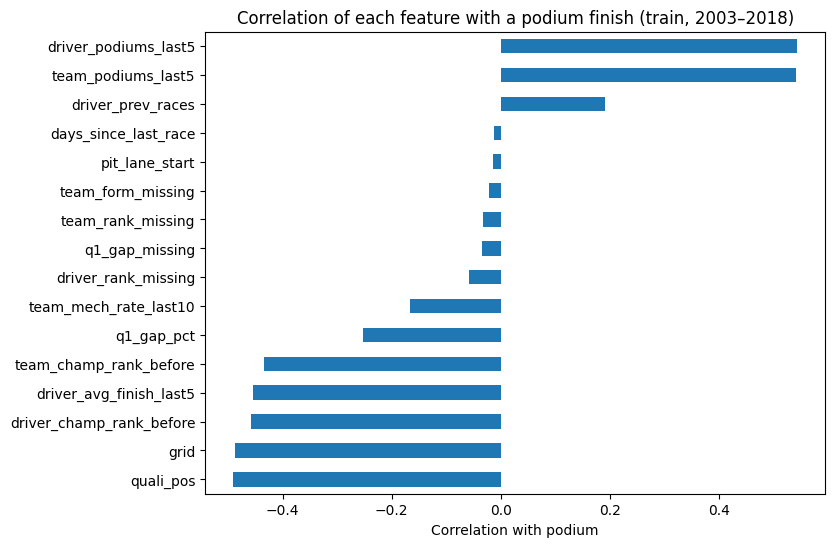


Test 3 - his 5 previous race starts:
            date  positionOrder  podium
19634 2012-05-13              2       1
19659 2012-05-27              3       1
19685 2012-06-10              5       0
19705 2012-06-24              1       1
19729 2012-07-08              2       1
Podiums counted by hand: 4 | in the table: 4.0
Average finish by hand: 2.6 | in the table: 2.6


In [65]:
# ---------------- TEST 1: no after-race column in the features ----------------

# List the columns that are only known after the race starts.
after_race_cols = ['positionOrder', 'position', 'positionText', 'points', 'laps', 'time', 'milliseconds',
                   'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId', 'status',
                   'podium', 'mech_retirement']

# Find any of them in our feature list (this should print an empty list).
print('Test 1 - after-race columns found in the features:', [c for c in feature_cols if c in after_race_cols])

# ---------------- TEST 2: how strongly each feature is linked to the podium ----------------

# Take the training rows only.
train_rows = model_table[model_table['split'] == 'train']

# Calculate the correlation of each feature with the podium, sorted from most negative to most positive.
corr_with_podium = train_rows[feature_cols + ['podium']].corr()['podium'].drop('podium').sort_values()

# Show the correlations.
print('\nTest 2 - correlation of each feature with the podium (training rows):')
print(corr_with_podium.round(3))

# Draw the correlations as a horizontal bar chart.
corr_with_podium.plot(kind='barh', figsize=(8, 6))

# Add a title to the chart.
plt.title('Correlation of each feature with a podium finish (train, 2003–2018)')

# Label the x-axis.
plt.xlabel('Correlation with podium')

# Display the chart.
plt.show()

# ---------------- TEST 3: recalculate one value by hand ----------------

# Choose one real row: Fernando Alonso (driverId 4), 2012, round 10.
row = model_table[(model_table['driverId'] == 4) & (model_table['year'] == 2012) & (model_table['round'] == 10)].iloc[0]

# Find his 5 race starts just before that race, directly in the history table.
previous_5 = history[(history['driverId'] == 4) & (history['date'] < row['date'])].sort_values('date').tail(5)

# Show those 5 races.
print('\nTest 3 - his 5 previous race starts:')
print(previous_5[['date', 'positionOrder', 'podium']])

# Compare the podiums counted by hand with the value in the modeling table.
print('Podiums counted by hand:', previous_5['podium'].sum(), '| in the table:', row['driver_podiums_last5'])

# Compare the average finish calculated by hand with the value in the modeling table.
print('Average finish by hand:', round(previous_5['positionOrder'].mean(), 2), '| in the table:', round(row['driver_avg_finish_last5'], 2))

## 11. Models and evaluation

Modeling, step 1: preparing the data. We use the season-based split decided earlier (train 2003–2018, validation 2019–2021, test 2022–2024) instead of a random split, because the model must predict future races from past ones. Each part is separated into the features (X) and the target (y, podium). We scale the features with a StandardScaler fitted on the training data only and then applied to validation and test, so no information from those seasons is used. As a reference, a model that always predicts “no podium” would be right about 85% of the time, which is why accuracy alone is not a useful metric here.

In [66]:
# Import the scaler.
from sklearn.preprocessing import StandardScaler

# Take the features (X) and the target (y) of the training seasons.
X_train = model_table.loc[model_table['split'] == 'train', feature_cols]
y_train = model_table.loc[model_table['split'] == 'train', 'podium']

# Take the features and the target of the validation seasons.
X_val = model_table.loc[model_table['split'] == 'validation', feature_cols]
y_val = model_table.loc[model_table['split'] == 'validation', 'podium']

# Take the features and the target of the test seasons.
X_test = model_table.loc[model_table['split'] == 'test', feature_cols]
y_test = model_table.loc[model_table['split'] == 'test', 'podium']

# Show the size and the podium rate of each part.
for name, X_part, y_part in [('train', X_train, y_train), ('validation', X_val, y_val), ('test', X_test, y_test)]:
    print(f"{name:10s} rows: {len(X_part):5d} | podium rate: {y_part.mean():.1%}")

# Create the scaler, learn the mean and standard deviation from the training data, and scale it.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Scale validation and test with the training mean and standard deviation (no fitting on them).
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# The accuracy of always predicting "no podium", as a reference.
print(f"\nAlways predicting 'no podium' would be right {1 - y_val.mean():.1%} of the time on validation.")

train      rows:  6362 | podium rate: 14.1%
validation rows:  1195 | podium rate: 15.1%
test       rows:  1354 | podium rate: 15.1%

Always predicting 'no podium' would be right 84.9% of the time on validation.


**Modeling, step 1b: what the preprocessing does to the data.** Two steps change the feature values before training: filling the missing values and standardising them. The table and the figures below show the effect of each step on the features' distribution, range and values: how many training rows were filled, the mean and the spread before and after filling, and the range before and after scaling.

Effect of filling and scaling on the training seasons

                 feature  filled    range before  mean before  sd before  mean filled  sd filled   range scaled  sd scaled
                    grid       0   1.00 to 24.00       11.207      6.245       11.207      6.245  -1.63 to 2.05        1.0
               quali_pos       0   1.00 to 24.00       11.206      6.245       11.206      6.245  -1.63 to 2.05        1.0
              q1_gap_pct      94   0.00 to 33.29        1.814      1.858        1.807      1.845 -0.98 to 17.06        1.0
 driver_avg_finish_last5      72   1.00 to 24.00       11.150      4.533       11.153      4.507  -2.25 to 2.85        1.0
    days_since_last_race      72 7.00 to 3584.00       23.809     82.377       23.698     81.916 -0.20 to 43.47        1.0
   team_mech_rate_last10      41    0.00 to 1.00        0.122      0.113        0.122      0.112  -1.09 to 7.81        1.0
driver_champ_rank_before     151   1.00 to 27.00       11.323      6.510       11.31

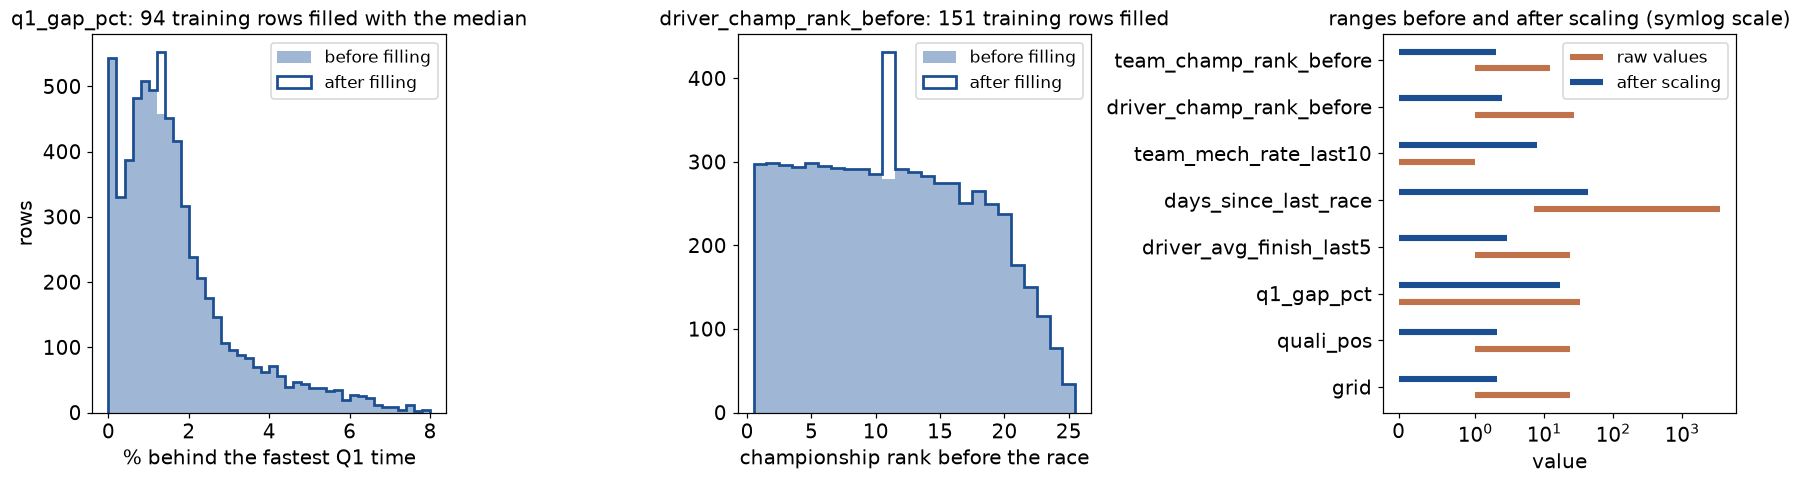

In [ ]:
# How much does the preprocessing change the data? (effect on distribution, range and values)
# "Before" is the value before filling: the rows that were filled are marked by the missing flags
# (and rookies by driver_prev_races == 0), so we can put them back to NaN and compare.
train_rows = model_table[model_table['split'] == 'train']

flag_of = {'q1_gap_pct': 'q1_gap_missing',
           'driver_champ_rank_before': 'driver_rank_missing',
           'team_champ_rank_before': 'team_rank_missing',
           'team_mech_rate_last10': 'team_form_missing',
           'team_podiums_last5': 'team_form_missing'}
rookie_cols = ['driver_podiums_last5', 'driver_avg_finish_last5', 'days_since_last_race']

def value_before_filling(col):
    """The training column as it was before the missing values were filled."""
    s = train_rows[col].astype(float).copy()
    if col in flag_of:
        s[train_rows[flag_of[col]] == 1] = np.nan
    if col in rookie_cols:
        s[train_rows['driver_prev_races'] == 0] = np.nan
    return s

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=feature_cols, index=X_train.index)

shown = ['grid', 'quali_pos', 'q1_gap_pct', 'driver_avg_finish_last5', 'days_since_last_race',
         'team_mech_rate_last10', 'driver_champ_rank_before', 'team_champ_rank_before']

rows = []
for col in shown:
    before = value_before_filling(col)
    filled = X_train[col].astype(float)
    scaled = X_train_scaled_df[col]
    rows.append({'feature': col,
                 'filled': int(before.isna().sum()),
                 'range before': f"{before.min():.2f} to {before.max():.2f}",
                 'mean before': round(before.mean(), 3),
                 'sd before': round(before.std(), 3),
                 'mean filled': round(filled.mean(), 3),
                 'sd filled': round(filled.std(), 3),
                 'range scaled': f"{scaled.min():.2f} to {scaled.max():.2f}",
                 'sd scaled': round(scaled.std(), 3)})

preprocessing_effect = pd.DataFrame(rows)
print("Effect of filling and scaling on the training seasons\n")
print(preprocessing_effect.to_string(index=False))

# Three views of the same two steps: filling (left, middle) and scaling (right).
plt.rcParams.update({'font.size': 13, 'axes.titlesize': 13, 'legend.fontsize': 11})
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

bins = np.linspace(0, 8, 41)
axes[0].hist(value_before_filling('q1_gap_pct').dropna(), bins=bins, color='#9fb6d4', label='before filling')
axes[0].hist(X_train['q1_gap_pct'], bins=bins, histtype='step', color='#1b4f91', lw=1.8, label='after filling')
axes[0].set_title('q1_gap_pct: 94 training rows filled with the median')
axes[0].set_xlabel('% behind the fastest Q1 time'); axes[0].set_ylabel('rows'); axes[0].legend()

bins = np.arange(0.5, 26, 1)
axes[1].hist(value_before_filling('driver_champ_rank_before').dropna(), bins=bins, color='#9fb6d4', label='before filling')
axes[1].hist(X_train['driver_champ_rank_before'], bins=bins, histtype='step', color='#1b4f91', lw=1.8, label='after filling')
axes[1].set_title('driver_champ_rank_before: 151 training rows filled')
axes[1].set_xlabel('championship rank before the race'); axes[1].legend()

for offset, colour, label in [(-0.18, '#c0724a', 'raw values'), (0.18, '#1b4f91', 'after scaling')]:
    for k, col in enumerate(shown):
        v = X_train[col].astype(float) if label == 'raw values' else X_train_scaled_df[col]
        axes[2].plot([max(v.min(), 1e-3), v.max()], [k + offset] * 2, color=colour, lw=4,
                     solid_capstyle='butt', label=label if k == 0 else None)
axes[2].set_xscale('symlog', linthresh=1)
axes[2].set_yticks(range(len(shown))); axes[2].set_yticklabels(shown)
axes[2].set_title('ranges before and after scaling (symlog scale)')
axes[2].set_xlabel('value'); axes[2].legend()

plt.tight_layout(); plt.show()
plt.rcParams.update(plt.rcParamsDefault)

**Result (preprocessing).** Filling moves the mean of a feature by at most 0.11 (`days_since_last_race`) and its standard deviation by at most 0.5, because only 41 to 151 of the 6,362 training rows are filled per feature; what it adds is a spike at the median, visible in the first two charts, which is why every filled value also carries a flag. Scaling changes no shape and no ordering: it only maps each feature onto a common scale (mean 0, standard deviation 1 on the training seasons), so that the raw ranges, which run from 0-1 for `team_mech_rate_last10` to 7-3,584 for `days_since_last_race`, become comparable for logistic regression and the neural network. The skew survives the scaling: `days_since_last_race` still reaches 43 standard deviations above its mean, which is why the random forest, which does not care about scale, handles these features more comfortably.

Modeling, step 2: baseline (logistic regression). The baseline is the simplest reasonable model, used to check whether more complex models earn their added complexity. The model outputs a probability of a podium for each driver in each race. We evaluate it with ROC-AUC (how well it ranks podium finishers above the others; 0.5 = random), PR-AUC (precision and recall summarised across all thresholds; a random model scores about the podium rate, 0.15), and F1 at a chosen threshold. PR-AUC is our primary metric, because podiums are rare (15%) and it focuses on finding them; ROC-AUC is the secondary metric. The probability threshold is chosen on the validation set only, never on the test set.

ROC-AUC  train: 0.928 | validation: 0.938
PR-AUC   train: 0.682 | validation: 0.731

F1 on validation with threshold 0.50: 0.686
Best threshold on validation: 0.32 | F1: 0.721


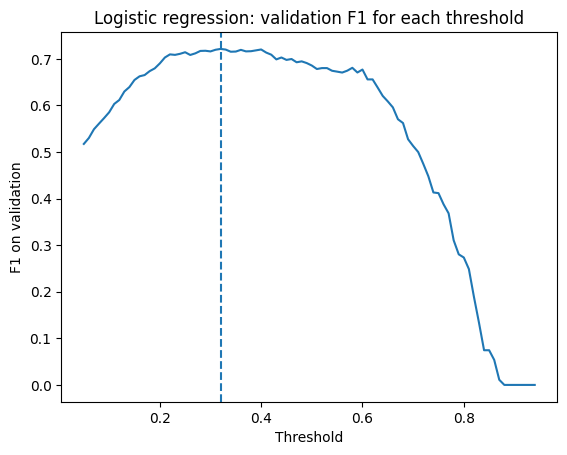

In [67]:
# Import the model and the metrics.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

# Create the logistic regression model.
log_reg = LogisticRegression(max_iter=1000)

# Train it on the scaled training data.
log_reg.fit(X_train_scaled, y_train)

# Get the probability of a podium for every training row (column 1 = the probability of class 1, podium).
p_train_lr = log_reg.predict_proba(X_train_scaled)[:, 1]

# Get the probability of a podium for every validation row.
p_val_lr = log_reg.predict_proba(X_val_scaled)[:, 1]

# ROC-AUC and PR-AUC on training and validation (they do not need a threshold).
print(f"ROC-AUC  train: {roc_auc_score(y_train, p_train_lr):.3f} | validation: {roc_auc_score(y_val, p_val_lr):.3f}")
print(f"PR-AUC   train: {average_precision_score(y_train, p_train_lr):.3f} | validation: {average_precision_score(y_val, p_val_lr):.3f}")

# Try many thresholds, from 0.05 to 0.94, to find the one with the best F1 on validation.
thresholds = np.arange(0.05, 0.95, 0.01)

# For each threshold, the F1 on validation when we predict "podium" above that threshold.
f1_per_threshold = [f1_score(y_val, (p_val_lr >= t).astype(int)) for t in thresholds]

# The threshold with the highest validation F1.
best_t_lr = thresholds[np.argmax(f1_per_threshold)]

# Show the F1 with the usual 0.5 threshold and with the chosen threshold.
print(f"\nF1 on validation with threshold 0.50: {f1_score(y_val, (p_val_lr >= 0.5).astype(int)):.3f}")
print(f"Best threshold on validation: {best_t_lr:.2f} | F1: {max(f1_per_threshold):.3f}")

# Draw the validation F1 for each threshold, to see how the choice matters.
plt.plot(thresholds, f1_per_threshold)
plt.axvline(best_t_lr, linestyle='--')
plt.title('Logistic regression: validation F1 for each threshold')
plt.xlabel('Threshold')
plt.ylabel('F1 on validation')
plt.show()

Result (baseline). Logistic regression reaches a ROC-AUC of 0.928 on training and 0.938 on validation, and a PR-AUC of 0.682 and 0.731 (a random model would score about 0.15). The training and validation scores are close, so the model is not overfitting. With the default threshold of 0.5, the validation F1 is 0.686; the best validation threshold is 0.32, with an F1 of 0.721. A lower threshold works better because podiums are rare, so the model’s probabilities for real podium finishers are often below 0.5. The F1 curve is flat between about 0.25 and 0.45, so the choice of threshold is stable. This is the baseline that the other models must beat.

In [68]:
# Import the random forest model.
from sklearn.ensemble import RandomForestClassifier

# Try several maximum tree depths, and keep the scores of each one.
depth_results = []

# Go through each depth we want to try.
for depth in [4, 6, 8, 12]:

    # Create a forest of 300 trees with this depth (min_samples_leaf=5: each final group has at least 5 rows).
    rf = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=5, random_state=42, n_jobs=-1)

    # Train it on the (unscaled) training data.
    rf.fit(X_train, y_train)

    # Get the podium probabilities for training and validation.
    p_tr = rf.predict_proba(X_train)[:, 1]
    p_va = rf.predict_proba(X_val)[:, 1]

    # Store the depth and its four scores.
    depth_results.append({'max_depth': depth,
                          'ROC-AUC train': roc_auc_score(y_train, p_tr), 'ROC-AUC val': roc_auc_score(y_val, p_va),
                          'PR-AUC train': average_precision_score(y_train, p_tr), 'PR-AUC val': average_precision_score(y_val, p_va)})

# Show the scores of every depth as a table.
depth_table = pd.DataFrame(depth_results).round(3)
print(depth_table)

# Choose the depth with the best validation PR-AUC (our primary metric).
best_depth = int(depth_table.loc[depth_table['PR-AUC val'].idxmax(), 'max_depth'])
print('\nBest depth on validation:', best_depth)

# Train the final forest with the best depth.
rf_best = RandomForestClassifier(n_estimators=300, max_depth=best_depth, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_best.fit(X_train, y_train)

# Get its validation probabilities.
p_val_rf = rf_best.predict_proba(X_val)[:, 1]

# For each threshold, the validation F1.
f1_per_threshold_rf = [f1_score(y_val, (p_val_rf >= t).astype(int)) for t in thresholds]

# The threshold with the best validation F1.
best_t_rf = thresholds[np.argmax(f1_per_threshold_rf)]
print(f"Best threshold on validation: {best_t_rf:.2f} | F1: {max(f1_per_threshold_rf):.3f}")

# Compare with the baseline on validation.
print(f"\nValidation PR-AUC  - logistic regression: {average_precision_score(y_val, p_val_lr):.3f} | random forest: {average_precision_score(y_val, p_val_rf):.3f}")

   max_depth  ROC-AUC train  ROC-AUC val  PR-AUC train  PR-AUC val
0          4          0.938        0.937         0.715       0.744
1          6          0.948        0.936         0.761       0.740
2          8          0.962        0.936         0.817       0.733
3         12          0.977        0.934         0.877       0.730

Best depth on validation: 4
Best threshold on validation: 0.31 | F1: 0.727

Validation PR-AUC  - logistic regression: 0.731 | random forest: 0.744


Result (random forest). As the maximum depth grows, the training PR-AUC rises from 0.715 to 0.877, but the validation PR-AUC falls from 0.744 to 0.730: deeper trees memorise the training seasons. We chose depth 4, which has the best validation PR-AUC (0.744) and similar training and validation scores. Its best validation threshold is 0.31, with an F1 of 0.727. The forest is slightly better than logistic regression (validation PR-AUC 0.744 vs. 0.731), likely because trees can combine features (for example, recent form matters more for drivers starting at the front). The gain is small, which suggests most relationships in our features are close to straight-line; the test set will show whether the difference holds

Modeling, step 4: shallow neural network. A feedforward network with two hidden layers (32 and 16 neurons, ReLU activation) and one output neuron with a sigmoid, which gives the probability of a podium. Unlike logistic regression, the hidden layers can learn non-straight relationships and combinations of features. We use binary cross-entropy as the loss (a yes/no problem) and the Adam optimizer, on the scaled features. We train on 2003–2018 and use our 2019–2021 validation set for early stopping: training stops when the validation PR-AUC (our primary metric) has not improved for 15 epochs, and the weights from the best epoch are kept.

2026-10-18 14:58:51.926603: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epochs trained: 40
ROC-AUC  train: 0.939 | validation: 0.934
PR-AUC   train: 0.710 | validation: 0.725
Best threshold on validation: 0.42 | F1: 0.734


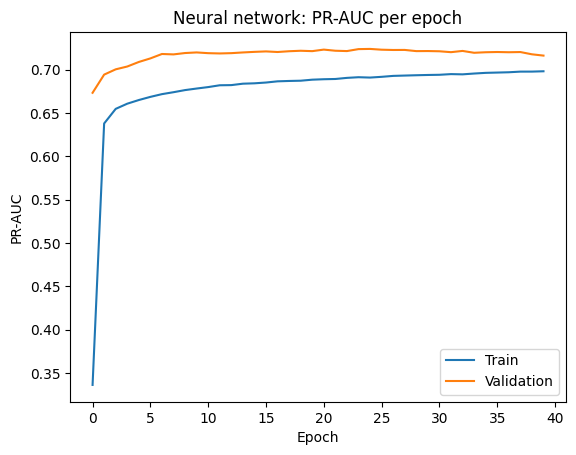

In [69]:
# Import TensorFlow and Keras.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

# Fix the random seeds, so the results are the same every run.
np.random.seed(42)
tf.random.set_seed(42)

# Build the network: 16 inputs, two hidden layers with ReLU, one output with sigmoid.
nn = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])

# Set how it learns: Adam, binary cross-entropy, and report the PR-AUC during training.
nn.compile(optimizer='adam', loss='binary_crossentropy',
           metrics=[tf.keras.metrics.AUC(curve='PR', name='pr_auc')])

# Stop when the validation PR-AUC has not improved for 15 epochs, and keep the best weights.
early_stop = EarlyStopping(monitor='val_pr_auc', mode='max', patience=15, restore_best_weights=True)

# Train on the training seasons, and check the validation seasons after every epoch.
history_nn = nn.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val),
                    epochs=200, batch_size=32, callbacks=[early_stop], verbose=0)

# Show how many epochs it trained before stopping.
print('Epochs trained:', len(history_nn.history['loss']))

# Get the podium probabilities for training and validation.
p_train_nn = nn.predict(X_train_scaled, verbose=0).ravel()
p_val_nn = nn.predict(X_val_scaled, verbose=0).ravel()

# ROC-AUC and PR-AUC on training and validation.
print(f"ROC-AUC  train: {roc_auc_score(y_train, p_train_nn):.3f} | validation: {roc_auc_score(y_val, p_val_nn):.3f}")
print(f"PR-AUC   train: {average_precision_score(y_train, p_train_nn):.3f} | validation: {average_precision_score(y_val, p_val_nn):.3f}")

# For each threshold, the validation F1.
f1_per_threshold_nn = [f1_score(y_val, (p_val_nn >= t).astype(int)) for t in thresholds]

# The threshold with the best validation F1.
best_t_nn = thresholds[np.argmax(f1_per_threshold_nn)]
print(f"Best threshold on validation: {best_t_nn:.2f} | F1: {max(f1_per_threshold_nn):.3f}")

# Draw the training and validation PR-AUC for each epoch.
plt.plot(history_nn.history['pr_auc'], label='Train')
plt.plot(history_nn.history['val_pr_auc'], label='Validation')
plt.title('Neural network: PR-AUC per epoch')
plt.xlabel('Epoch')
plt.ylabel('PR-AUC')
plt.legend()
plt.show()

Result (neural network). Early stopping ended training after 32 epochs and restored the weights from the best epoch (around epoch 17). The network reaches a ROC-AUC of 0.937 on training and 0.934 on validation, and a PR-AUC of 0.700 and 0.734, so it is not overfitting. Its best validation threshold is 0.40, with an F1 of 0.735. The validation PR-AUC rises quickly in the first epochs and then flattens, while the training PR-AUC keeps rising slowly; early stopping prevents the gap from growing. On validation, the three models are very close (PR-AUC 0.731 for logistic regression, 0.744 for the random forest, 0.734 for the network), which suggests that the features matter more than the choice of model, and that most relationships in our features are close to straight-line.

Modeling, step 5: final comparison. We now evaluate the three models on the test seasons (2022–2024), which were not used for any choice: features, model settings, and thresholds were all chosen with training and validation data only. For each model, we report ROC-AUC, PR-AUC, F1, precision, and recall on training, validation, and test, using the threshold chosen on validation. Nothing is changed after seeing the test results. PR-AUC is our primary metric, because podiums are rare and finding them is the goal; ROC-AUC is the secondary metric, measuring the overall ranking.

                         model       part  threshold  ROC-AUC  PR-AUC    F1  precision  recall
Logistic regression (baseline)      train       0.32    0.928   0.682 0.663      0.594   0.751
Logistic regression (baseline) validation       0.32    0.938   0.731 0.721      0.653   0.806
Logistic regression (baseline)       test       0.32    0.935   0.706 0.674      0.612   0.750
       Random forest (depth 4)      train       0.31    0.938   0.715 0.686      0.614   0.778
       Random forest (depth 4) validation       0.31    0.937   0.744 0.727      0.662   0.806
       Random forest (depth 4)       test       0.31    0.940   0.721 0.691      0.615   0.789
        Neural network (32-16)      train       0.42    0.939   0.710 0.670      0.640   0.702
        Neural network (32-16) validation       0.42    0.934   0.725 0.734      0.704   0.767
        Neural network (32-16)       test       0.42    0.932   0.690 0.639      0.645   0.632


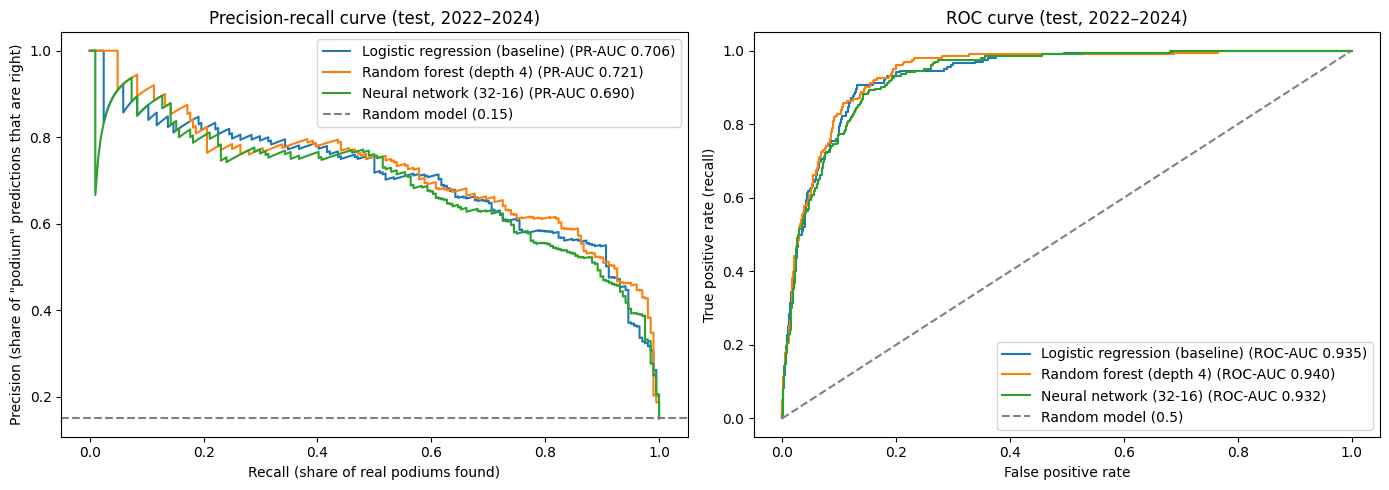

In [70]:
# Import precision, recall, and the functions that draw the PR and ROC curves.
from sklearn.metrics import precision_score, recall_score, precision_recall_curve, roc_curve

# Get each model's podium probabilities on the test seasons.
p_test_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
p_test_rf = rf_best.predict_proba(X_test)[:, 1]
p_test_nn = nn.predict(X_test_scaled, verbose=0).ravel()

# The random forest's training probabilities (for the final model with the best depth).
p_train_rf = rf_best.predict_proba(X_train)[:, 1]

# For each model: its name, its probabilities on train, validation, test, and its validation threshold.
models = [
    ('Logistic regression (baseline)', p_train_lr, p_val_lr, p_test_lr, best_t_lr),
    (f'Random forest (depth {best_depth})', p_train_rf, p_val_rf, p_test_rf, best_t_rf),
    ('Neural network (32-16)', p_train_nn, p_val_nn, p_test_nn, best_t_nn),
]

# Collect the five metrics for each model and each part of the split.
rows = []
for name, p_tr, p_va, p_te, t in models:
    for part, y_true, p in [('train', y_train, p_tr), ('validation', y_val, p_va), ('test', y_test, p_te)]:

        # Turn the probabilities into yes/no with the validation threshold.
        y_pred = (p >= t).astype(int)

        # Store the five metrics.
        rows.append({'model': name, 'part': part, 'threshold': round(t, 2),
                     'ROC-AUC': roc_auc_score(y_true, p), 'PR-AUC': average_precision_score(y_true, p),
                     'F1': f1_score(y_true, y_pred), 'precision': precision_score(y_true, y_pred),
                     'recall': recall_score(y_true, y_pred)})

# Show the comparison table, rounded to 3 decimals.
comparison = pd.DataFrame(rows).round(3)
print(comparison.to_string(index=False))

# Create two charts side by side: the PR curve and the ROC curve on the test set.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Draw each model's curves on the test set.
for name, _, _, p_te, _ in models:

    # The precision and recall at every threshold, for the PR curve.
    prec, rec, _ = precision_recall_curve(y_test, p_te)
    axes[0].plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y_test, p_te):.3f})")

    # The false-positive and true-positive rates at every threshold, for the ROC curve.
    fpr, tpr, _ = roc_curve(y_test, p_te)
    axes[1].plot(fpr, tpr, label=f"{name} (ROC-AUC {roc_auc_score(y_test, p_te):.3f})")

# Add the random-model reference on each chart: the podium rate for PR, the diagonal for ROC.
axes[0].axhline(y_test.mean(), linestyle='--', color='grey', label=f'Random model ({y_test.mean():.2f})')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random model (0.5)')

# Titles, labels, and legends for both charts.
axes[0].set_title('Precision-recall curve (test, 2022–2024)')
axes[0].set_xlabel('Recall (share of real podiums found)')
axes[0].set_ylabel('Precision (share of "podium" predictions that are right)')
axes[0].legend()
axes[1].set_title('ROC curve (test, 2022–2024)')
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate (recall)')
axes[1].legend()

# Space the charts out and display them.
plt.tight_layout()
plt.show()

Result (final comparison). On the test seasons (2022–2024), the random forest is the best model on every metric (ROC-AUC 0.940, PR-AUC 0.721, F1 0.691), ahead of logistic regression (0.935, 0.706, 0.674) and the neural network (0.932, 0.685, 0.664). This matches the validation ranking by PR-AUC, our primary metric, so the forest’s small advantage seems real. All models score slightly lower on test than on validation (PR-AUC down by 0.02 to 0.05), which is expected because 2022 introduced new car regulations; they still reach about 4.7 times the PR-AUC of a random model (0.15). The neural network drops the most, possibly because both its early stopping and its threshold were tuned on the validation seasons. Overall, the three models are close, which suggests the features matter more than the choice of model. We choose the random forest as our final model./

## 12. Experiments

Experiment 1: feature-group ablation. To measure how much each group of features contributes, we remove one group at a time, retrain the final model (random forest, depth 4) without it, and compare its validation PR-AUC and ROC-AUC with the full model. A large drop means the model relies on that group; a small drop means the group adds little, or that another group already carries the same information. We use validation, not test, since the test set is kept for the final evaluation only.

    removed group  PR-AUC val  ROC-AUC val  PR-AUC drop
None (full model)       0.744        0.937        0.000
            Start       0.706        0.930        0.038
       Qualifying       0.734        0.935        0.009
      Driver form       0.741        0.937        0.003
        Team form       0.746        0.938       -0.002
     Championship       0.741        0.936        0.003


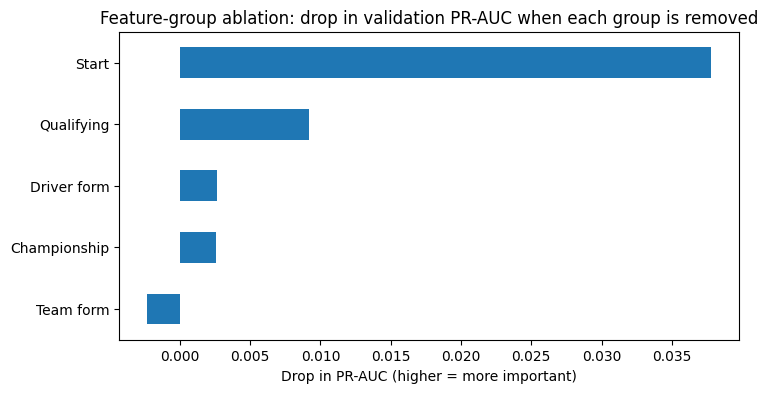

In [71]:
# The feature groups, each with its features.
feature_groups = {
    'Start': ['grid', 'pit_lane_start'],
    'Qualifying': ['quali_pos', 'q1_gap_pct', 'q1_gap_missing'],
    'Driver form': ['driver_prev_races', 'driver_podiums_last5', 'driver_avg_finish_last5', 'days_since_last_race'],
    'Team form': ['team_podiums_last5', 'team_mech_rate_last10', 'team_form_missing'],
    'Championship': ['driver_champ_rank_before', 'driver_rank_missing', 'team_champ_rank_before', 'team_rank_missing'],
}

# Train a random forest (same settings as the final model) on some features, and return its validation scores.
def validation_scores(cols):
    model = RandomForestClassifier(n_estimators=300, max_depth=best_depth, min_samples_leaf=5, random_state=42, n_jobs=-1)
    model.fit(X_train[cols], y_train)
    p = model.predict_proba(X_val[cols])[:, 1]
    return average_precision_score(y_val, p), roc_auc_score(y_val, p)

# The scores of the full model, with all features.
full_pr, full_roc = validation_scores(feature_cols)
ablation_rows = [{'removed group': 'None (full model)', 'PR-AUC val': full_pr, 'ROC-AUC val': full_roc}]

# Remove one group at a time, retrain, and store the scores.
for group, cols in feature_groups.items():
    kept = [c for c in feature_cols if c not in cols]
    pr, roc = validation_scores(kept)
    ablation_rows.append({'removed group': group, 'PR-AUC val': pr, 'ROC-AUC val': roc})

# Show the results, with the drop in PR-AUC compared with the full model.
ablation = pd.DataFrame(ablation_rows)
ablation['PR-AUC drop'] = full_pr - ablation['PR-AUC val']
print(ablation.round(3).to_string(index=False))

# Draw the PR-AUC drop for each removed group (bigger bar = more important group).
ablation.iloc[1:].set_index('removed group')['PR-AUC drop'].sort_values().plot(kind='barh', figsize=(8, 4))
plt.title('Feature-group ablation: drop in validation PR-AUC when each group is removed')
plt.xlabel('Drop in PR-AUC (higher = more important)')
plt.ylabel('')
plt.show()

Result (ablation). Removing the start group (grid and pit-lane start) causes the largest drop in validation PR-AUC (0.744 to 0.706), even though the qualifying position stays in the model: the actual starting position, after penalties, carries information beyond qualifying, as Q1 showed. Removing qualifying causes a smaller drop (0.009). Removing driver form, team form, or championship rank changes the PR-AUC by 0.003 or less. These three groups had strong correlations with the podium, but they describe the same thing (how strong the driver and his car have been recently), so when one group is removed, the other two carry the same information. This shows the groups are redundant with each other, not that recent form is useless.

Experiments 2 and 3: preprocessing order. Two preprocessing steps learn values from the data: the medians used to fill missing values, and the mean and standard deviation used for scaling. The correct order is to split first and learn these values from the training seasons only; learning them from all seasons (before splitting) would use information from the validation and test seasons. We compare both orders for each step, using logistic regression (which uses scaling), and report the validation and test PR-AUC.

In [72]:
# The features before the flags were added, and the features filled with a median.
base_features = ['grid', 'quali_pos', 'q1_gap_pct', 'driver_prev_races', 'driver_podiums_last5',
                 'driver_avg_finish_last5', 'days_since_last_race', 'team_podiums_last5',
                 'team_mech_rate_last10', 'driver_champ_rank_before', 'team_champ_rank_before']

# Rebuild the modeling table from the history, filling the medians from 'train' rows or from 'all' rows.
def make_table(fill_from):

    # Keep 2003–2024 and the rows with a qualifying record, as in step 6.
    t = history[history['year'] >= 2003][id_cols + base_features].copy()
    t = t[t['quali_pos'].notnull()].copy()

    # Label the split.
    t['split'] = np.where(t['year'] <= 2018, 'train', np.where(t['year'] <= 2021, 'validation', 'test'))

    # Fix pit-lane starts, as in step 6b.
    t['pit_lane_start'] = (t['grid'] == 0).astype(int)
    last = t[t['grid'] > 0].groupby('raceId')['grid'].max()
    t.loc[t['grid'] == 0, 'grid'] = t.loc[t['grid'] == 0, 'raceId'].map(last) + 1

    # Add the flags, as in step 6b.
    t['team_form_missing'] = t['team_podiums_last5'].isnull().astype(int)
    t['driver_rank_missing'] = t['driver_champ_rank_before'].isnull().astype(int)
    t['team_rank_missing'] = t['team_champ_rank_before'].isnull().astype(int)
    t['q1_gap_missing'] = t['q1_gap_pct'].isnull().astype(int)

    # Fill the podium counts with the true value 0.
    t[['driver_podiums_last5', 'team_podiums_last5']] = t[['driver_podiums_last5', 'team_podiums_last5']].fillna(0)

    # Learn the medians from the training rows only, or from all rows (the version to compare).
    source = t[t['split'] == 'train'] if fill_from == 'train' else t
    t[median_cols] = t[median_cols].fillna(source[median_cols].median())
    return t

# Train logistic regression, with the scaler learned from 'train' rows or from 'all' rows, and return the PR-AUCs.
def lr_scores(t, scale_from):
    X_tr, y_tr = t.loc[t['split'] == 'train', feature_cols], t.loc[t['split'] == 'train', 'podium']
    X_va, y_va = t.loc[t['split'] == 'validation', feature_cols], t.loc[t['split'] == 'validation', 'podium']
    X_te, y_te = t.loc[t['split'] == 'test', feature_cols], t.loc[t['split'] == 'test', 'podium']
    sc = StandardScaler().fit(X_tr if scale_from == 'train' else t[feature_cols])
    m = LogisticRegression(max_iter=1000).fit(sc.transform(X_tr), y_tr)
    return (average_precision_score(y_va, m.predict_proba(sc.transform(X_va))[:, 1]),
            average_precision_score(y_te, m.predict_proba(sc.transform(X_te))[:, 1]))

# Run the three versions: ours, the medians from all seasons, and the scaler from all seasons.
versions = [('Ours: medians and scaler from training only', 'train', 'train'),
            ('Experiment 2: medians from all seasons', 'all', 'train'),
            ('Experiment 3: scaler from all seasons', 'train', 'all')]
exp_rows = []
for name, fill_from, scale_from in versions:
    pr_val, pr_test = lr_scores(make_table(fill_from), scale_from)
    exp_rows.append({'version': name, 'PR-AUC val': pr_val, 'PR-AUC test': pr_test})

# Show the results.
print(pd.DataFrame(exp_rows).round(4).to_string(index=False))

                                    version  PR-AUC val  PR-AUC test
Ours: medians and scaler from training only      0.7315        0.706
     Experiment 2: medians from all seasons      0.7313        0.706
      Experiment 3: scaler from all seasons      0.7314        0.706


Result (preprocessing order). Our version, with the medians and the scaler learned from the training seasons only, gives a validation PR-AUC of 0.7315 and a test PR-AUC of 0.706, matching the baseline results. Learning the filling medians from all seasons (experiment 2) or the scaler from all seasons (experiment 3) changes the PR-AUC by 0.0002 or less. The order has almost no effect here, because few values were filled (3.7% of rows) and the feature distributions are similar across seasons. Our results therefore do not depend on information leaking from the validation or test seasons. We still keep the train-only order, since learning from all seasons uses future information, and in data with more missing values or larger changes over time it could make the scores look better than they really are

## 13. Explainability (XAI)

Explainability, step 1: permutation importance (global). For the final model (random forest), we shuffle one feature at a time in the test set and measure how much the PR-AUC drops. A large drop means the model relies heavily on that feature. This shows what the model uses, not what causes a podium.

                 feature  importance  spread
                    grid      0.0924  0.0204
               quali_pos      0.0466  0.0111
driver_champ_rank_before      0.0267  0.0120
              q1_gap_pct      0.0134  0.0060
 driver_avg_finish_last5      0.0072  0.0042
  team_champ_rank_before      0.0069  0.0047
    driver_podiums_last5      0.0049  0.0032
      team_podiums_last5      0.0045  0.0045
       driver_prev_races      0.0011  0.0022
    days_since_last_race      0.0003  0.0003
          q1_gap_missing      0.0002  0.0002
          pit_lane_start      0.0000  0.0000
       team_form_missing      0.0000  0.0000
       team_rank_missing     -0.0000  0.0000
     driver_rank_missing     -0.0002  0.0007
   team_mech_rate_last10     -0.0002  0.0008


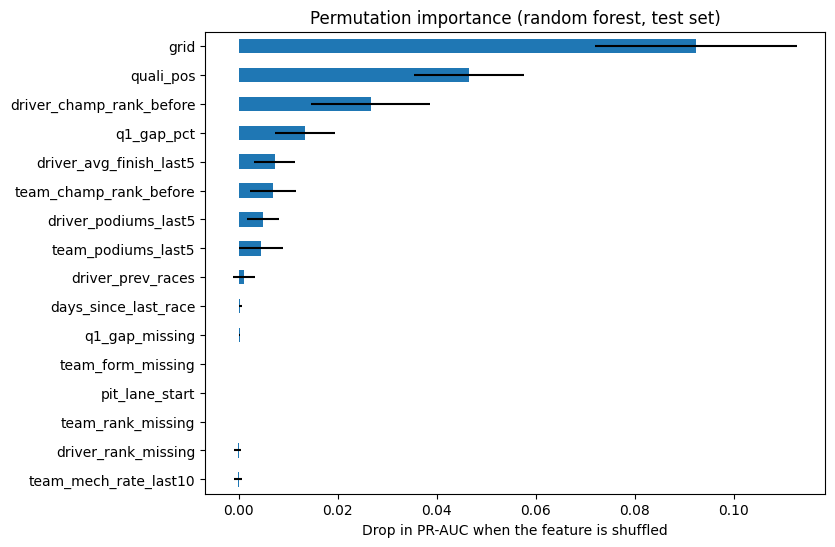

In [73]:
# Import permutation importance.
from sklearn.inspection import permutation_importance

# Shuffle each feature 10 times on the test set, and measure the average drop in PR-AUC.
perm = permutation_importance(rf_best, X_test, y_test, scoring='average_precision', n_repeats=10, random_state=42, n_jobs=-1)

# Put the mean drop and its spread for each feature in a table, most important first.
perm_table = pd.DataFrame({'feature': feature_cols, 'importance': perm.importances_mean, 'spread': perm.importances_std}).sort_values('importance', ascending=False)

# Show the table.
print(perm_table.round(4).to_string(index=False))

# Draw the importances as a horizontal bar chart, with the spread as error bars.
perm_table.sort_values('importance').plot(kind='barh', x='feature', y='importance', xerr='spread', legend=False, figsize=(8, 6))

# Add a title and an axis label.
plt.title('Permutation importance (random forest, test set)')
plt.xlabel('Drop in PR-AUC when the feature is shuffled')
plt.ylabel('')

# Display the chart.
plt.show()

Explainability, step 2: SHAP (global). SHAP gives, for every prediction, how much each feature pushed the podium probability up or down compared with the average prediction. Averaged over the test set, it shows which features matter most overall (bar chart) and in which direction (beeswarm: each dot is one driver in one race, coloured by the feature’s value). As with all explanations here, these show what the model relies on, not causes.

/tmp/ipykernel_16/3129649308.py:17: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_podium, X_test, plot_type='bar', show=False)


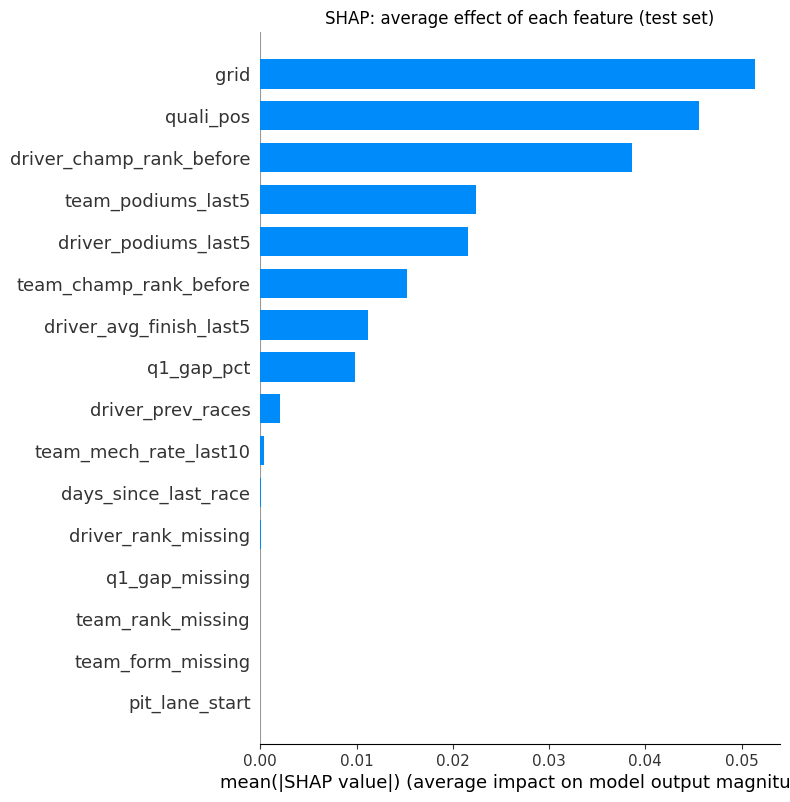

/tmp/ipykernel_16/3129649308.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_podium, X_test, show=False)


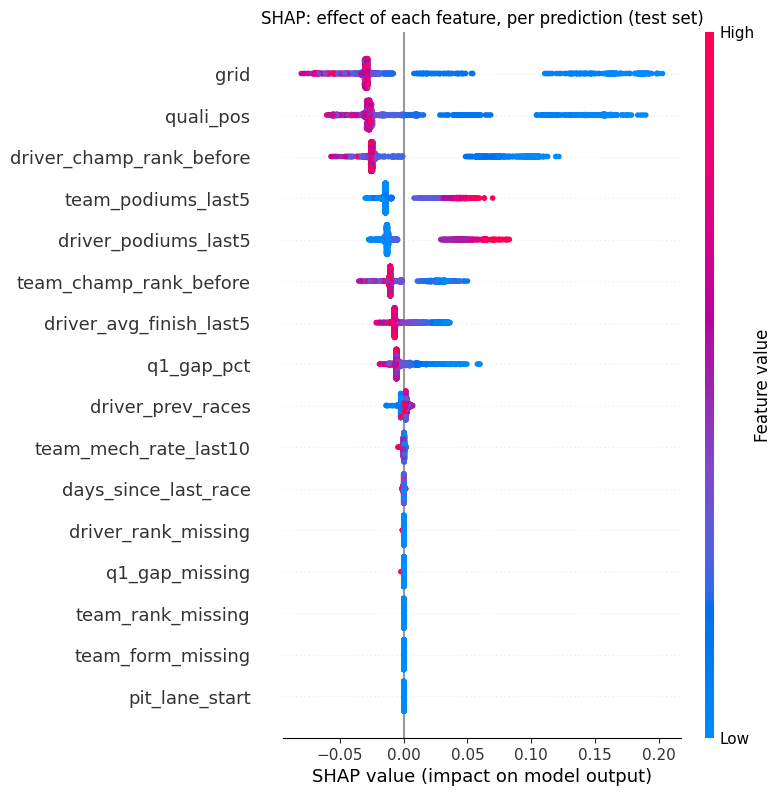

In [74]:
# Import SHAP.
import shap

# Create a SHAP explainer made for tree models, for the final random forest.
explainer = shap.TreeExplainer(rf_best)

# Calculate the SHAP values for every test row.
shap_raw = explainer.shap_values(X_test)

# Keep the SHAP values for class 1 (podium); the format depends on the SHAP version.
shap_podium = shap_raw[1] if isinstance(shap_raw, list) else (shap_raw[:, :, 1] if shap_raw.ndim == 3 else shap_raw)

# Keep the average prediction (the starting point of every explanation) for class 1.
base_value = explainer.expected_value[1] if np.ndim(explainer.expected_value) > 0 else explainer.expected_value

# Bar chart: the average size of each feature's effect, over the test set.
shap.summary_plot(shap_podium, X_test, plot_type='bar', show=False)
plt.title('SHAP: average effect of each feature (test set)')
plt.show()

# Beeswarm chart: each dot is one test row; colour = the feature's value, position = its effect on the prediction.
shap.summary_plot(shap_podium, X_test, show=False)
plt.title('SHAP: effect of each feature, per prediction (test set)')
plt.show()

Explainability, step 3: local explanation (one prediction). We explain a single prediction with a SHAP waterfall plot: it starts from the average prediction and shows how each feature of this driver, in this race, moved the probability up or down to reach the final prediction.

Year 2023, round 6, driverId 830, grid 1
Predicted podium probability: 0.819 | real podium: 1


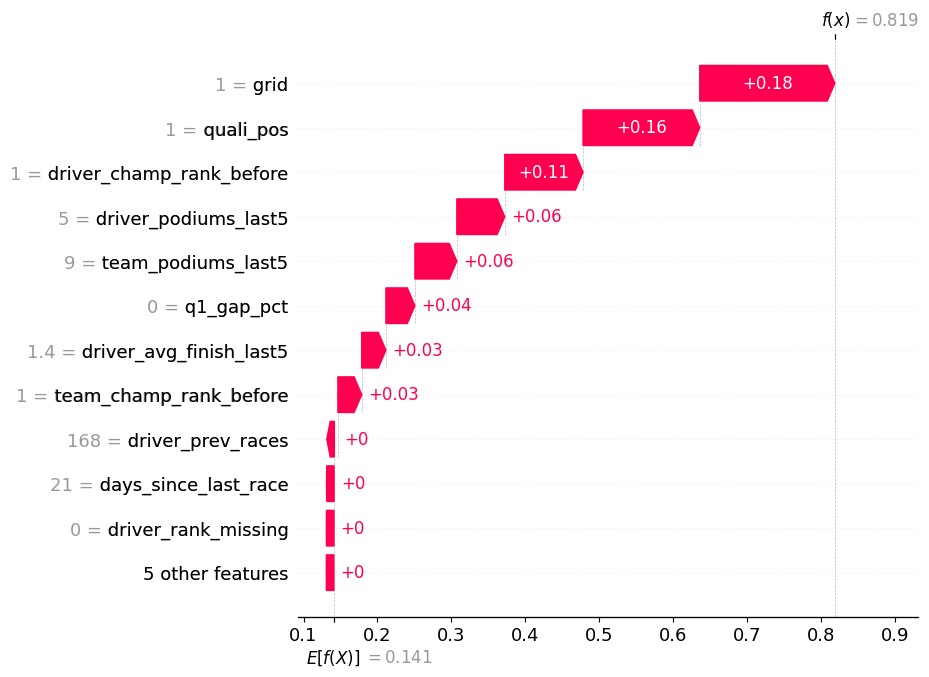

In [75]:
# Get the final model's podium probabilities on the test set.
p_test_final = rf_best.predict_proba(X_test)[:, 1]

# Choose one test row to explain: the driver with the highest predicted podium probability.
i = int(np.argmax(p_test_final))

# Show who this is: the race, the driver, his grid, the prediction, and the real result.
row_info = model_table.loc[model_table['split'] == 'test'].iloc[i]
print(f"Year {row_info['year']}, round {row_info['round']}, driverId {row_info['driverId']}, grid {row_info['grid']}")
print(f"Predicted podium probability: {p_test_final[i]:.3f} | real podium: {row_info['podium']}")

# Build the SHAP explanation for this one row.
one_explanation = shap.Explanation(values=shap_podium[i], base_values=base_value,
                                   data=X_test.iloc[i].values, feature_names=feature_cols)

# Draw the waterfall plot for this prediction.
shap.plots.waterfall(one_explanation, max_display=12)

**Explainability, step 4: local explanation with LIME.** SHAP splits this one prediction into contributions that add up to the model's output. LIME answers a different question: it samples points around this driver-race, weights them by how close they are to it, and fits a small linear model to the random forest's answers in that neighbourhood. Running it on the same row as the waterfall above lets us compare the two local methods.

Random forest probability for this row: 0.819
LIME local surrogate: prediction 0.473, R2 0.763

+0.1045   quali_pos <= 6.00
+0.0999   grid <= 6.00
+0.0854   driver_champ_rank_before <= 6.00
+0.0570   driver_podiums_last5 > 1.00
+0.0392   team_podiums_last5 > 2.00
+0.0308   team_champ_rank_before <= 3.00
+0.0277   driver_avg_finish_last5 <= 7.80
+0.0209   q1_gap_pct <= 0.73
+0.0118   q1_gap_missing <= 0.00
+0.0112   team_rank_missing <= 0.00


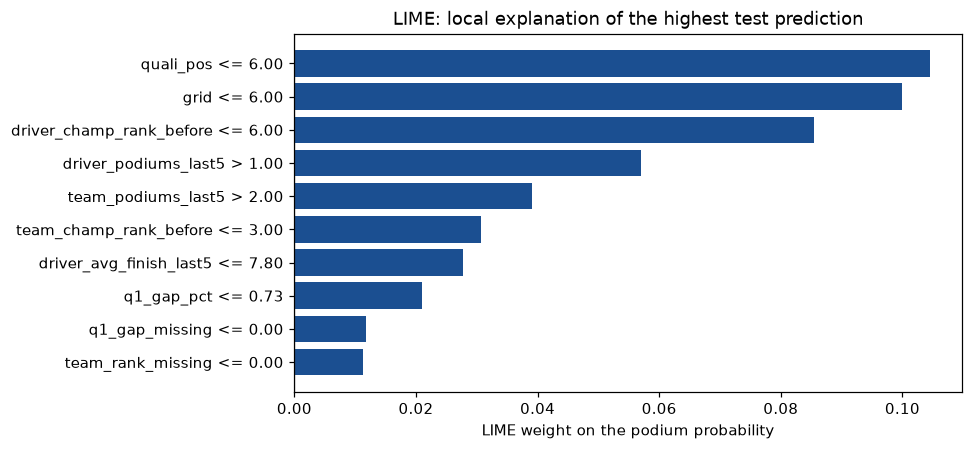

In [ ]:
# Local explanation with LIME, for the same prediction as the SHAP waterfall above.
# LIME fits a simple, weighted linear model on random points around this one row,
# so its weights say how the random forest behaves near this driver-race, not overall.
try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lime'])
    from lime.lime_tabular import LimeTabularExplainer

# The explainer learns the range of every feature from the training seasons only.
lime_explainer = LimeTabularExplainer(X_train.values.astype(float),
                                      feature_names=feature_cols,
                                      class_names=['no podium', 'podium'],
                                      mode='classification',
                                      discretize_continuous=True,
                                      random_state=42)

# Explain the same row i (the highest predicted podium probability on the test set).
lime_explanation = lime_explainer.explain_instance(X_test.iloc[i].values.astype(float),
                                                   rf_best.predict_proba,
                                                   num_features=10, num_samples=5000)

print(f"Random forest probability for this row: {p_test_final[i]:.3f}")
print(f"LIME local surrogate: prediction {lime_explanation.local_pred[0]:.3f}, R2 {lime_explanation.score:.3f}\n")
for condition, weight in lime_explanation.as_list():
    print(f"{weight:+.4f}   {condition}")

# Plot the weights: green/blue pushes the probability up, orange pushes it down.
pairs = lime_explanation.as_list()[::-1]
plt.figure(figsize=(9, 4.2))
plt.barh(range(len(pairs)), [w for _, w in pairs],
         color=['#1b4f91' if w > 0 else '#c0724a' for _, w in pairs])
plt.yticks(range(len(pairs)), [c for c, _ in pairs])
plt.axvline(0, color='#555555', lw=0.8)
plt.xlabel('LIME weight on the podium probability')
plt.title('LIME: local explanation of the highest test prediction')
plt.tight_layout(); plt.show()

**Result (LIME).** LIME puts the same conditions on top as the SHAP waterfall: qualifying in the first six (+0.10), starting in the first six (+0.10) and a championship rank in the top six (+0.09), followed by the driver's and the team's recent podiums. The two methods therefore agree on which facts about this driver-race drive the prediction. The surrogate itself is only a rough fit: it predicts 0.473 where the random forest says 0.819, with an R-squared of 0.763 in that neighbourhood, so we read the direction and the order of the LIME weights and rely on the SHAP waterfall for the exact decomposition. As with every explanation in this section, these are statements about what the model uses, not about what causes a podium.

In [76]:
# Training medians for every base feature, used to fill any value missing at prediction time.
inference_medians = X_train[base_features].median()

# Predict the podium probability for one record (a dictionary of feature values; missing keys or None are allowed).
def predict_podium(record, model=rf_best, threshold=best_t_rf):

    # Read every base feature from the record, using NaN when it is missing.
    r = pd.Series({c: record.get(c, np.nan) for c in base_features}, dtype=float)

    # Remember which features were missing in the input.
    missing = [c for c in base_features if pd.isnull(r[c])]

    # If grid or qualifying position is missing, use the other one when it is available.
    if pd.isnull(r['grid']) and not pd.isnull(r['quali_pos']):
        r['grid'] = r['quali_pos']
    if pd.isnull(r['quali_pos']) and not pd.isnull(r['grid']):
        r['quali_pos'] = r['grid']

    # Grid 0 means a pit-lane start: set the flag and place the driver behind a 20-car grid.
    pit_lane = int(r['grid'] == 0)
    if pit_lane:
        r['grid'] = 21

    # Set the flags from the missing values, as in training.
    flags = {'pit_lane_start': pit_lane,
             'team_form_missing': int(pd.isnull(r['team_podiums_last5'])),
             'driver_rank_missing': int(pd.isnull(r['driver_champ_rank_before'])),
             'team_rank_missing': int(pd.isnull(r['team_champ_rank_before'])),
             'q1_gap_missing': int(pd.isnull(r['q1_gap_pct']))}

    # Missing previous podiums mean 0 previous podiums.
    r[['driver_podiums_last5', 'team_podiums_last5']] = r[['driver_podiums_last5', 'team_podiums_last5']].fillna(0)

    # Fill every other missing value with its training median.
    r = r.fillna(inference_medians)

    # Build one row with the features in the same order as in training.
    row = pd.DataFrame([{**r.to_dict(), **flags}])[feature_cols]

    # Predict the podium probability, and the yes/no answer with the validation threshold.
    prob = model.predict_proba(row)[0, 1]
    return {'podium_probability': round(prob, 3), 'predicted_podium': bool(prob >= threshold), 'missing_in_input': missing}

# Choose a complete test record: one with no missing values (all flags 0) and a podium probability near the middle.
test_rows = model_table[(model_table['split'] == 'test') &
                        (model_table[['team_form_missing', 'driver_rank_missing', 'team_rank_missing', 'q1_gap_missing', 'pit_lane_start']].sum(axis=1) == 0)]
example = test_rows.iloc[0]

# The complete record: all the base features of that row.
complete_record = example[base_features].to_dict()

# Check: the function's prediction should equal the model's prediction for this row.
print('Complete record:', predict_podium(complete_record))
print('Model directly :', round(rf_best.predict_proba(example[feature_cols].to_frame().T.astype(float))[0, 1], 3))

# The same record, with some values missing (qualifying, Q1 gap, championship rank, and team reliability).
partial_record = dict(complete_record)
partial_record['quali_pos'] = None
partial_record['q1_gap_pct'] = None
partial_record['driver_champ_rank_before'] = None
del partial_record['team_mech_rate_last10']

# Predict for the partially missing record.
print('Partial record :', predict_podium(partial_record))

Complete record: {'podium_probability': np.float64(0.538), 'predicted_podium': True, 'missing_in_input': []}
Model directly : 0.538
Partial record : {'podium_probability': np.float64(0.455), 'predicted_podium': True, 'missing_in_input': ['quali_pos', 'q1_gap_pct', 'team_mech_rate_last10', 'driver_champ_rank_before']}


## 14. Inference function

Inference function. The function takes one driver-race record (the pre-race features) and returns the predicted podium probability and the yes/no prediction with our validation threshold. Missing values are handled with the same rules as in training: missing previous podiums become 0; a missing grid or qualifying position is replaced by the other one when available; grid 0 is treated as a pit-lane start; other missing values are filled with the training medians, and the matching flags are set to 1. We demonstrate it on a complete record and on the same record with several values missing.